
from pathlib import Path

# Find the original dataset inside the project
project_folder = Path.cwd()
raw_folder = project_folder / "data" / "raw"

print("Current notebook location:")
print(project_folder)

print("\nDoes the raw data folder exist?")
print(raw_folder.exists())

print("\nFiles found in the raw folder:")
if raw_folder.exists():
    for file in raw_folder.iterdir():
        print(file.name)
else:
    print("Raw folder not found. Check the notebook location.")


In [2]:

import pandas as pd

# Path to the copied original workbook
file_path = raw_folder / "pcos_original.xlsx"

# Open the Excel workbook without modifying it
excel_file = pd.ExcelFile(file_path)

print("WORKBOOK INSPECTION")
print("-" * 40)

print("\nSheet names:")
print(excel_file.sheet_names)

print("\nDimensions of each sheet:")
for sheet in excel_file.sheet_names:
    df_temp = pd.read_excel(file_path, sheet_name=sheet)
    print(f"{sheet}: {df_temp.shape[0]} rows, {df_temp.shape[1]} columns")


WORKBOOK INSPECTION
----------------------------------------

Sheet names:
['Instructions', 'Full_new']

Dimensions of each sheet:
Instructions: 20 rows, 4 columns
Full_new: 541 rows, 45 columns


In [3]:

# Load the actual PCOS dataset
df = pd.read_excel(file_path, sheet_name="Full_new")

print("DATASET SHAPE:")
print(df.shape)

print("\nCOLUMN NAMES:")
for number, column in enumerate(df.columns, start=1):
    print(f"{number}. {column}")

print("\nFIRST 5 ROWS:")
display(df.head())

print("\nDATA TYPES:")
print(df.dtypes)


DATASET SHAPE:
(541, 45)

COLUMN NAMES:
1. Sl. No
2. Patient File No.
3. PCOS (Y/N)
4.  Age (yrs)
5. Weight (Kg)
6. Height(Cm) 
7. BMI
8. Blood Group
9. Pulse rate(bpm) 
10. RR (breaths/min)
11. Hb(g/dl)
12. Cycle(R/I)
13. Cycle length(days)
14. Marraige Status (Yrs)
15. Pregnant(Y/N)
16. No. of aborptions
17.   I   beta-HCG(mIU/mL)
18. II    beta-HCG(mIU/mL)
19. FSH(mIU/mL)
20. LH(mIU/mL)
21. FSH/LH
22. Hip(inch)
23. Waist(inch)
24. Waist:Hip Ratio
25. TSH (mIU/L)
26. AMH(ng/mL)
27. PRL(ng/mL)
28. Vit D3 (ng/mL)
29. PRG(ng/mL)
30. RBS(mg/dl)
31. Weight gain(Y/N)
32. hair growth(Y/N)
33. Skin darkening (Y/N)
34. Hair loss(Y/N)
35. Pimples(Y/N)
36. Fast food (Y/N)
37. Reg.Exercise(Y/N)
38. BP _Systolic (mmHg)
39. BP _Diastolic (mmHg)
40. Follicle No. (L)
41. Follicle No. (R)
42. Avg. F size (L) (mm)
43. Avg. F size (R) (mm)
44. Endometrium (mm)
45. Unnamed: 44

FIRST 5 ROWS:


,Sl. No,Patient File No.,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),...,Fast food (Y/N),Reg.Exercise(Y/N),BP _Systolic (mmHg),BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm),Unnamed: 44
0,1,1,0,28,44.6,152.0,19.300000,15,78,22,...,1.0,0,110,80,3,3,18.0,18.0,8.5,NaN
1,2,2,0,36,65.0,161.5,24.921163,15,74,20,...,0.0,0,120,70,3,5,15.0,14.0,3.7,NaN
2,3,3,1,33,68.8,165.0,25.270891,11,72,18,...,1.0,0,120,80,13,15,18.0,20.0,10.0,NaN
3,4,4,0,37,65.0,148.0,29.674945,13,72,20,...,0.0,0,120,70,2,2,15.0,14.0,7.5,NaN
4,5,5,0,25,52.0,161.0,20.060954,11,72,18,...,0.0,0,120,80,3,4,16.0,14.0,7.0,NaN



DATA TYPES:
Sl. No                      int64
Patient File No.            int64
PCOS (Y/N)                  int64
 Age (yrs)                  int64
Weight (Kg)               float64
Height(Cm)                float64
BMI                       float64
Blood Group                 int64
Pulse rate(bpm)             int64
RR (breaths/min)            int64
Hb(g/dl)                  float64
Cycle(R/I)                  int64
Cycle length(days)          int64
Marraige Status (Yrs)     float64
Pregnant(Y/N)               int64
No. of aborptions           int64
  I   beta-HCG(mIU/mL)    float64
II    beta-HCG(mIU/mL)     object
FSH(mIU/mL)               float64
LH(mIU/mL)                float64
FSH/LH                    float64
Hip(inch)                   int64
Waist(inch)                 int64
Waist:Hip Ratio           float64
TSH (mIU/L)               float64
AMH(ng/mL)                 object
PRL(ng/mL)                float64
Vit D3 (ng/mL)            float64
PRG(ng/mL)                float64
R

In [4]:

# STEP 1: Missing values in each column

missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage (%)": missing_percent.round(2)
})

missing_report = missing_report.sort_values(
    by="Missing Values", ascending=False
)

print("MISSING-VALUE REPORT")
display(missing_report)

# STEP 2: Duplicate rows

print("\nDUPLICATE ROWS")
print("Number of completely duplicated rows:", df.duplicated().sum())

# STEP 3: Completely empty columns

empty_columns = df.columns[df.isnull().all()].tolist()

print("\nCOMPLETELY EMPTY COLUMNS")
print(empty_columns)

# STEP 4: Target distribution

print("\nPCOS TARGET DISTRIBUTION")
print(df["PCOS (Y/N)"].value_counts(dropna=False))

print("\nTARGET DISTRIBUTION IN PERCENTAGE")
print(
    (df["PCOS (Y/N)"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)


MISSING-VALUE REPORT


,Missing Values,Missing Percentage (%)
Unnamed: 44,539,99.63
Marraige Status (Yrs),1,0.18
Fast food (Y/N),1,0.18
Patient File No.,0,0.00
Sl. No,0,0.00
Height(Cm),0,0.00
BMI,0,0.00
Blood Group,0,0.00
Pulse rate(bpm),0,0.00
RR (breaths/min),0,0.00



DUPLICATE ROWS
Number of completely duplicated rows: 0

COMPLETELY EMPTY COLUMNS
[]

PCOS TARGET DISTRIBUTION
PCOS (Y/N)
0    364
1    177
Name: count, dtype: int64

TARGET DISTRIBUTION IN PERCENTAGE
PCOS (Y/N)
0    67.28
1    32.72
Name: proportion, dtype: float64


In [5]:

# Inspect the suspicious columns without changing them

suspicious_columns = [
    "II    beta-HCG(mIU/mL)",
    "AMH(ng/mL)",
    "Unnamed: 44"
]

for column in suspicious_columns:
    print("\n" + "=" * 60)
    print("COLUMN:", repr(column))
    print("Data type:", df[column].dtype)
    print("Non-missing unique values (first 20):")

    values = df[column].dropna().unique()
    print(values[:20])

    print("\nNumber of unique non-missing values:", len(values))



COLUMN: 'II    beta-HCG(mIU/mL)'
Data type: object
Non-missing unique values (first 20):
[1.99 494.08 801.45 100.51 158.51 1214.23 91.55 749.98 218.65 13 610.63
 4490.18 11.24 15 768.03 12 10 20 30.66 1455]

Number of unique non-missing values: 203

COLUMN: 'AMH(ng/mL)'
Data type: object
Non-missing unique values (first 20):
[2.07 1.53 6.63 1.22 2.26 6.74 3.05 1.54 1 1.61 4.47 1.67 7.94 2.38 0.88
 0.69 3.78 1.92 2.85 2.13]

Number of unique non-missing values: 301

COLUMN: 'Unnamed: 44'
Data type: object
Non-missing unique values (first 20):
['.' 7]

Number of unique non-missing values: 2


In [8]:

# Inspect suspicious values safely without modifying the dataset

beta_col = "II    beta-HCG(mIU/mL)"
amh_col = "AMH(ng/mL)"
unnamed_col = "Unnamed: 44"

# 1. Beta-HCG: identify non-numeric entries
beta_numeric = pd.to_numeric(df[beta_col], errors="coerce")
beta_bad_mask = beta_numeric.isna() & df[beta_col].notna()

print("BETA-HCG: NON-NUMERIC ENTRIES")
print("Number of entries:", int(beta_bad_mask.sum()))
print(df.loc[beta_bad_mask, beta_col].to_string())

# 2. AMH: identify non-numeric entries
amh_numeric = pd.to_numeric(df[amh_col], errors="coerce")
amh_bad_mask = amh_numeric.isna() & df[amh_col].notna()

print("\nAMH: NON-NUMERIC ENTRIES")
print("Number of entries:", int(amh_bad_mask.sum()))
print(df.loc[amh_bad_mask, amh_col].to_string())

# 3. Unnamed column: show its non-missing entries
unnamed_mask = df[unnamed_col].notna()

print("\nUNNAMED COLUMN: NON-MISSING ENTRIES")
print("Number of entries:", int(unnamed_mask.sum()))
print(df.loc[unnamed_mask, unnamed_col].to_string())

print("\nOriginal row indices:")
print(df.index[unnamed_mask].tolist())



BETA-HCG: NON-NUMERIC ENTRIES
Number of entries: 1
123    1.99.

AMH: NON-NUMERIC ENTRIES
Number of entries: 1
305    a

UNNAMED COLUMN: NON-MISSING ENTRIES
Number of entries: 2
180    .
363    7

Original row indices:
[180, 363]


In [9]:

# Inspect selected rows before cleaning
print("BETA-HCG ENTRY — ROW INDEX 123")
display(df.iloc[[123]].T)

print("\nAMH ENTRY — ROW INDEX 305")
display(df.iloc[[305]].T)

print("\nUNNAMED COLUMN ENTRY — ROW INDEX 180")
display(df.iloc[[180]].T)

print("\nUNNAMED COLUMN ENTRY — ROW INDEX 363")
display(df.iloc[[363]].T)


BETA-HCG ENTRY — ROW INDEX 123


,123
Sl. No,124
Patient File No.,124
PCOS (Y/N),1
Age (yrs),23
Weight (Kg),40.0
Height(Cm),150.0
BMI,17.777778
Blood Group,15
Pulse rate(bpm),74
RR (breaths/min),18



AMH ENTRY — ROW INDEX 305


,305
Sl. No,306
Patient File No.,306
PCOS (Y/N),0
Age (yrs),37
Weight (Kg),56.0
Height(Cm),152.0
BMI,24.238227
Blood Group,13
Pulse rate(bpm),74
RR (breaths/min),20



UNNAMED COLUMN ENTRY — ROW INDEX 180


,180
Sl. No,181
Patient File No.,181
PCOS (Y/N),1
Age (yrs),30
Weight (Kg),70.0
Height(Cm),150.0
BMI,31.111111
Blood Group,16
Pulse rate(bpm),74
RR (breaths/min),18



UNNAMED COLUMN ENTRY — ROW INDEX 363


,363
Sl. No,364
Patient File No.,364
PCOS (Y/N),0
Age (yrs),31
Weight (Kg),48.0
Height(Cm),152.0
BMI,20.8
Blood Group,17
Pulse rate(bpm),72
RR (breaths/min),18


In [10]:

from pathlib import Path
import pandas as pd

# Create the processed-data folder if it does not exist
processed_folder = project_folder / "data" / "processed"
processed_folder.mkdir(parents=True, exist_ok=True)

# Work on a copy; do not modify the original DataFrame
df_clean = df.copy()

# Keep a record of every cleaning decision
cleaning_log = []

# 1. Correct the obvious trailing punctuation in beta-HCG
beta_col = "II    beta-HCG(mIU/mL)"

original_beta = df_clean.loc[123, beta_col]
df_clean.loc[123, beta_col] = "1.99"

cleaning_log.append({
    "Column": beta_col,
    "Row_Index": 123,
    "Original_Value": original_beta,
    "Action": "Removed trailing punctuation; interpreted as 1.99",
    "Reason": "The entry appears to be a numeric value with a trailing period"
})

# 2. Convert the invalid AMH text to missing
amh_col = "AMH(ng/mL)"

original_amh = df_clean.loc[305, amh_col]
df_clean.loc[305, amh_col] = pd.NA

cleaning_log.append({
    "Column": amh_col,
    "Row_Index": 305,
    "Original_Value": original_amh,
    "Action": "Replaced with missing value",
    "Reason": "The text entry cannot be interpreted reliably as a numeric measurement"
})

# 3. Exclude the mostly empty, unnamed column
unnamed_col = "Unnamed: 44"
unnamed_values = df_clean[unnamed_col].dropna().to_dict()

df_clean = df_clean.drop(columns=[unnamed_col])

cleaning_log.append({
    "Column": unnamed_col,
    "Row_Index": "Multiple",
    "Original_Value": str(unnamed_values),
    "Action": "Column excluded from processed dataset",
    "Reason": "Uninformative column name; 539 of 541 values are missing"
})

# 4. Convert the two numeric-looking clinical columns safely
df_clean[beta_col] = pd.to_numeric(
    df_clean[beta_col], errors="coerce"
)
df_clean[amh_col] = pd.to_numeric(
    df_clean[amh_col], errors="coerce"
)

# 5. Save processed data and audit log
cleaned_path = processed_folder / "pcos_cleaned.csv"
log_path = processed_folder / "cleaning_log.csv"

df_clean.to_csv(cleaned_path, index=False)
pd.DataFrame(cleaning_log).to_csv(log_path, index=False)

print("CLEANING COMPLETE")
print("Processed dataset:", cleaned_path)
print("Cleaning log:", log_path)
print("Original shape:", df.shape)
print("Processed shape:", df_clean.shape)
print("Original DataFrame unchanged:", df.shape == (541, 45))
print("Remaining missing values in processed data:",
      int(df_clean.isna().sum().sum()))


CLEANING COMPLETE
Processed dataset: C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\data\processed\pcos_cleaned.csv
Cleaning log: C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\data\processed\cleaning_log.csv
Original shape: (541, 45)
Processed shape: (541, 44)
Original DataFrame unchanged: True
Remaining missing values in processed data: 3


In [11]:

# Reload the saved processed dataset
df_check = pd.read_csv(cleaned_path)

print("PROCESSED DATASET SHAPE")
print(df_check.shape)

print("\nTARGET DISTRIBUTION")
print(df_check["PCOS (Y/N)"].value_counts(dropna=False))

print("\nREMAINING MISSING VALUES")
print(df_check.isna().sum()[df_check.isna().sum() > 0])

print("\nCHECK CLEANED COLUMNS")
print("Unnamed: 44 removed:", "Unnamed: 44" not in df_check.columns)
print("Target retained:", "PCOS (Y/N)" in df_check.columns)
print("Patient identifiers retained for audit:",
      "Sl. No" in df_check.columns and "Patient File No." in df_check.columns)

print("\nCHECK CLEANING LOG")
log_check = pd.read_csv(log_path)
display(log_check)

print("\nALL EXPECTED FILES EXIST")
for path in [cleaned_path, log_path]:
    print(path.name, ":", path.exists())


PROCESSED DATASET SHAPE
(541, 44)

TARGET DISTRIBUTION
PCOS (Y/N)
0    364
1    177
Name: count, dtype: int64

REMAINING MISSING VALUES
Marraige Status (Yrs)    1
AMH(ng/mL)               1
Fast food (Y/N)          1
dtype: int64

CHECK CLEANED COLUMNS
Unnamed: 44 removed: True
Target retained: True
Patient identifiers retained for audit: True

CHECK CLEANING LOG


,Column,Row_Index,Original_Value,Action,Reason
0,II beta-HCG(mIU/mL),123,1.99.,Removed trailing punctuation; interpreted as 1.99,The entry appears to be a numeric value with a...
1,AMH(ng/mL),305,a,Replaced with missing value,The text entry cannot be interpreted reliably ...
2,Unnamed: 44,Multiple,"{180: '.', 363: 7}",Column excluded from processed dataset,Uninformative column name; 539 of 541 values a...



ALL EXPECTED FILES EXIST
pcos_cleaned.csv : True
cleaning_log.csv : True


In [12]:

# Step 13: Feature audit (no model training)

target_col = "PCOS (Y/N)"

identifier_cols = [
    "Sl. No",
    "Patient File No."
]

# Columns that may be derived from other measurements.
# These are flagged for review, not automatically removed.
derived_or_redundant_candidates = [
    "BMI",
    "FSH/LH",
    "Waist:Hip Ratio"
]

# Confirm that the expected columns exist
required_cols = identifier_cols + [target_col]
missing_required = [col for col in required_cols if col not in df_check.columns]

if missing_required:
    print("Missing required columns:", missing_required)
else:
    print("All required identifier and target columns are present.")

# Create candidate feature list
excluded_cols = identifier_cols + [target_col]
candidate_features = [
    col for col in df_check.columns
    if col not in excluded_cols
]

print("\nDATASET OVERVIEW")
print("Total columns:", len(df_check.columns))
print("Identifier columns:", identifier_cols)
print("Target column:", target_col)
print("Candidate feature count:", len(candidate_features))

print("\nCANDIDATE FEATURES")
for number, col in enumerate(candidate_features, start=1):
    print(f"{number}. {col}")

print("\nFEATURES FLAGGED FOR REDUNDANCY REVIEW")
for col in derived_or_redundant_candidates:
    if col in candidate_features:
        print("-", col)

# Check whether the identifier values look unique
print("\nIDENTIFIER CHECK")
for col in identifier_cols:
    print(
        col,
        "| unique values:", df_check[col].nunique(dropna=False),
        "| rows:", len(df_check)
    )

# Check the target labels
print("\nTARGET LABEL CHECK")
print(df_check[target_col].value_counts(dropna=False))


All required identifier and target columns are present.

DATASET OVERVIEW
Total columns: 44
Identifier columns: ['Sl. No', 'Patient File No.']
Target column: PCOS (Y/N)
Candidate feature count: 41

CANDIDATE FEATURES
1.  Age (yrs)
2. Weight (Kg)
3. Height(Cm) 
4. BMI
5. Blood Group
6. Pulse rate(bpm) 
7. RR (breaths/min)
8. Hb(g/dl)
9. Cycle(R/I)
10. Cycle length(days)
11. Marraige Status (Yrs)
12. Pregnant(Y/N)
13. No. of aborptions
14.   I   beta-HCG(mIU/mL)
15. II    beta-HCG(mIU/mL)
16. FSH(mIU/mL)
17. LH(mIU/mL)
18. FSH/LH
19. Hip(inch)
20. Waist(inch)
21. Waist:Hip Ratio
22. TSH (mIU/L)
23. AMH(ng/mL)
24. PRL(ng/mL)
25. Vit D3 (ng/mL)
26. PRG(ng/mL)
27. RBS(mg/dl)
28. Weight gain(Y/N)
29. hair growth(Y/N)
30. Skin darkening (Y/N)
31. Hair loss(Y/N)
32. Pimples(Y/N)
33. Fast food (Y/N)
34. Reg.Exercise(Y/N)
35. BP _Systolic (mmHg)
36. BP _Diastolic (mmHg)
37. Follicle No. (L)
38. Follicle No. (R)
39. Avg. F size (L) (mm)
40. Avg. F size (R) (mm)
41. Endometrium (mm)

FEATURES FLAG

In [13]:

# STEP 14.1: FEATURE-TYPE AND LEAKAGE AUDIT

import pandas as pd
import numpy as np

audit_df = pd.read_csv(cleaned_path)

# A. Check categorical feature values
categorical_candidates = [
    "Blood Group",
    "Cycle(R/I)",
    "Pregnant(Y/N)",
    "Weight gain(Y/N)",
    "hair growth(Y/N)",
    "Skin darkening (Y/N)",
    "Hair loss(Y/N)",
    "Pimples(Y/N)",
    "Fast food (Y/N)",
    "Reg.Exercise(Y/N)"
]

print("=" * 60)
print("A. CATEGORICAL FEATURE VALUES")
print("=" * 60)

for col in categorical_candidates:
    if col in audit_df.columns:
        print(f"\n{col}")
        print(audit_df[col].value_counts(dropna=False).to_string())

# B. Check the three potentially derived measurements
def check_ratio(name, observed, calculated):
    observed = pd.to_numeric(observed, errors="coerce")
    calculated = pd.to_numeric(calculated, errors="coerce")

    comparison = pd.DataFrame({
        "observed": observed,
        "calculated": calculated
    }).replace([np.inf, -np.inf], np.nan).dropna()

    if comparison.empty:
        print(f"\n{name}: no comparable values")
        return

    difference = (
        comparison["observed"] - comparison["calculated"]
    ).abs()

    print(f"\n{name}")
    print("Comparable rows:", len(comparison))
    print("Mean absolute difference:", round(difference.mean(), 4))
    print("Median absolute difference:", round(difference.median(), 4))
    print("Rows differing by more than 0.1:", int((difference > 0.1).sum()))

print("\n" + "=" * 60)
print("B. DERIVED MEASUREMENT CHECKS")
print("=" * 60)

weight = pd.to_numeric(audit_df["Weight (Kg)"], errors="coerce")
height = pd.to_numeric(audit_df["Height(Cm) "], errors="coerce") / 100

check_ratio(
    "BMI",
    audit_df["BMI"],
    weight / height.pow(2)
)

fsh = pd.to_numeric(audit_df["FSH(mIU/mL)"], errors="coerce")
lh = pd.to_numeric(audit_df["LH(mIU/mL)"], errors="coerce")

check_ratio(
    "FSH/LH",
    audit_df["FSH/LH"],
    fsh / lh.replace(0, np.nan)
)

waist = pd.to_numeric(audit_df["Waist(inch)"], errors="coerce")
hip = pd.to_numeric(audit_df["Hip(inch)"], errors="coerce")

check_ratio(
    "Waist:Hip Ratio",
    audit_df["Waist:Hip Ratio"],
    waist / hip.replace(0, np.nan)
)

# C. Check for invalid or infinite numeric values
print("\n" + "=" * 60)
print("C. NUMERIC VALUE CHECK")
print("=" * 60)

numeric_df = audit_df.select_dtypes(include=np.number)

print("Infinite values per column:")
infinite_counts = pd.Series(
    np.isinf(numeric_df).sum(),
    index=numeric_df.columns
)
print(infinite_counts[infinite_counts > 0])

print("\nAudit completed. No dataset values have been modified.")


A. CATEGORICAL FEATURE VALUES

Blood Group
Blood Group
15    206
13    135
11    108
17     42
16     19
14     16
12     13
18      2

Cycle(R/I)
Cycle(R/I)
2    390
4    150
5      1

Pregnant(Y/N)
Pregnant(Y/N)
0    335
1    206

Weight gain(Y/N)
Weight gain(Y/N)
0    337
1    204

hair growth(Y/N)
hair growth(Y/N)
0    393
1    148

Skin darkening (Y/N)
Skin darkening (Y/N)
0    375
1    166

Hair loss(Y/N)
Hair loss(Y/N)
0    296
1    245

Pimples(Y/N)
Pimples(Y/N)
0    276
1    265

Fast food (Y/N)
Fast food (Y/N)
1.0    278
0.0    262
NaN      1

Reg.Exercise(Y/N)
Reg.Exercise(Y/N)
0    407
1    134

B. DERIVED MEASUREMENT CHECKS

BMI
Comparable rows: 541
Mean absolute difference: 0.0194
Median absolute difference: 0.0
Rows differing by more than 0.1: 6

FSH/LH
Comparable rows: 541
Mean absolute difference: 0.0001
Median absolute difference: 0.0
Rows differing by more than 0.1: 0

Waist:Hip Ratio
Comparable rows: 541
Mean absolute difference: 0.0
Median absolute difference: 0.0


In [14]:

# STEP 14.2: Display categorical values and derived-feature checks

import pandas as pd
import numpy as np

audit_df = pd.read_csv(cleaned_path)

# A. Categorical values
categorical_candidates = [
    "Blood Group",
    "Cycle(R/I)",
    "Pregnant(Y/N)",
    "Weight gain(Y/N)",
    "hair growth(Y/N)",
    "Skin darkening (Y/N)",
    "Hair loss(Y/N)",
    "Pimples(Y/N)",
    "Fast food (Y/N)",
    "Reg.Exercise(Y/N)"
]

print("SECTION A: CATEGORICAL VALUES")

for col in categorical_candidates:
    if col in audit_df.columns:
        print(f"\n{col}")
        print(audit_df[col].value_counts(dropna=False).to_string())

# B. Derived measurement checks
def compare_values(name, observed, calculated):
    observed = pd.to_numeric(observed, errors="coerce")
    calculated = pd.to_numeric(calculated, errors="coerce")

    comparison = pd.DataFrame({
        "Observed": observed,
        "Calculated": calculated
    }).replace([np.inf, -np.inf], np.nan).dropna()

    if comparison.empty:
        print(f"\n{name}: no comparable values")
        return

    difference = (
        comparison["Observed"] - comparison["Calculated"]
    ).abs()

    print(f"\n{name}")
    print("Comparable rows:", len(comparison))
    print("Mean absolute difference:", round(difference.mean(), 4))
    print("Median absolute difference:", round(difference.median(), 4))
    print("Differences greater than 0.1:", int((difference > 0.1).sum()))

print("\nSECTION B: DERIVED MEASUREMENT CHECKS")

weight = pd.to_numeric(audit_df["Weight (Kg)"], errors="coerce")
height = pd.to_numeric(audit_df["Height(Cm) "], errors="coerce") / 100

compare_values("BMI", audit_df["BMI"], weight / height.pow(2))

fsh = pd.to_numeric(audit_df["FSH(mIU/mL)"], errors="coerce")
lh = pd.to_numeric(audit_df["LH(mIU/mL)"], errors="coerce")

compare_values(
    "FSH/LH",
    audit_df["FSH/LH"],
    fsh / lh.replace(0, np.nan)
)

waist = pd.to_numeric(audit_df["Waist(inch)"], errors="coerce")
hip = pd.to_numeric(audit_df["Hip(inch)"], errors="coerce")

compare_values(
    "Waist:Hip Ratio",
    audit_df["Waist:Hip Ratio"],
    waist / hip.replace(0, np.nan)
)


SECTION A: CATEGORICAL VALUES

Blood Group
Blood Group
15    206
13    135
11    108
17     42
16     19
14     16
12     13
18      2

Cycle(R/I)
Cycle(R/I)
2    390
4    150
5      1

Pregnant(Y/N)
Pregnant(Y/N)
0    335
1    206

Weight gain(Y/N)
Weight gain(Y/N)
0    337
1    204

hair growth(Y/N)
hair growth(Y/N)
0    393
1    148

Skin darkening (Y/N)
Skin darkening (Y/N)
0    375
1    166

Hair loss(Y/N)
Hair loss(Y/N)
0    296
1    245

Pimples(Y/N)
Pimples(Y/N)
0    276
1    265

Fast food (Y/N)
Fast food (Y/N)
1.0    278
0.0    262
NaN      1

Reg.Exercise(Y/N)
Reg.Exercise(Y/N)
0    407
1    134

SECTION B: DERIVED MEASUREMENT CHECKS

BMI
Comparable rows: 541
Mean absolute difference: 0.0194
Median absolute difference: 0.0
Differences greater than 0.1: 6

FSH/LH
Comparable rows: 541
Mean absolute difference: 0.0001
Median absolute difference: 0.0
Differences greater than 0.1: 0

Waist:Hip Ratio
Comparable rows: 541
Mean absolute difference: 0.0
Median absolute difference: 0.

In [15]:

# STEP 14.3: Investigate BMI discrepancies

import pandas as pd
import numpy as np

audit_df = pd.read_csv(cleaned_path)

weight = pd.to_numeric(audit_df["Weight (Kg)"], errors="coerce")
height_m = pd.to_numeric(audit_df["Height(Cm) "], errors="coerce") / 100
recorded_bmi = pd.to_numeric(audit_df["BMI"], errors="coerce")

calculated_bmi = weight / height_m.pow(2)

bmi_audit = pd.DataFrame({
    "Row_Index": audit_df.index,
    "Weight_Kg": weight,
    "Height_Cm": height_m * 100,
    "Recorded_BMI": recorded_bmi,
    "Calculated_BMI": calculated_bmi
})

bmi_audit["Absolute_Difference"] = (
    bmi_audit["Recorded_BMI"] - bmi_audit["Calculated_BMI"]
).abs()

bmi_audit = bmi_audit.replace([np.inf, -np.inf], np.nan)

print("BMI rows differing by more than 0.1:")
display(
    bmi_audit.loc[
        bmi_audit["Absolute_Difference"] > 0.1
    ].sort_values("Absolute_Difference", ascending=False)
)

print("\nNo data has been changed.")


BMI rows differing by more than 0.1:


,Row_Index,Weight_Kg,Height_Cm,Recorded_BMI,Calculated_BMI,Absolute_Difference
440,440,56.0,160.0,20.3,21.875000,1.575000
402,402,65.0,158.0,25.0,26.037494,1.037494
481,481,66.1,148.0,30.8,30.177137,0.622863
412,412,55.0,152.0,23.2,23.805402,0.605402
517,517,59.0,152.0,25.2,25.536704,0.336704
313,313,50.0,161.0,19.1,19.289379,0.189379



No data has been changed.


In [16]:

# STEP 14.5: Save the provisional feature-group plan

import pandas as pd

reports_folder = project_folder / "reports"
reports_folder.mkdir(parents=True, exist_ok=True)

feature_groups = {
    "Physical and metabolic": [
        "Age (yrs)", "Weight (Kg)", "Height(Cm) ", "BMI",
        "Pulse rate(bpm) ", "RR (breaths/min)", "Hb(g/dl)",
        "Hip(inch)", "Waist(inch)", "TSH (mIU/L)",
        "RBS(mg/dl)", "BP _Systolic (mmHg)",
        "BP _Diastolic (mmHg)"
    ],
    "Hormonal and biochemical": [
        "I   beta-HCG(mIU/mL)", "II    beta-HCG(mIU/mL)",
        "FSH(mIU/mL)", "LH(mIU/mL)", "FSH/LH",
        "AMH(ng/mL)", "PRL(ng/mL)", "Vit D3 (ng/mL)",
        "PRG(ng/mL)"
    ],
    "Menstrual and reproductive history": [
        "Cycle(R/I)", "Cycle length(days)",
        "Marraige Status (Yrs)", "Pregnant(Y/N)",
        "No. of aborptions"
    ],
    "Symptoms and lifestyle": [
        "Weight gain(Y/N)", "hair growth(Y/N)",
        "Skin darkening (Y/N)", "Hair loss(Y/N)",
        "Pimples(Y/N)", "Fast food (Y/N)",
        "Reg.Exercise(Y/N)"
    ],
    "Ovarian measurements": [
        "Follicle No. (L)", "Follicle No. (R)",
        "Avg. F size (L) (mm)", "Avg. F size (R) (mm)",
        "Endometrium (mm)"
    ]
}

# Verify that all planned feature names exist in the dataset
all_columns = set(audit_df.columns)
plan_rows = []

for group_name, columns in feature_groups.items():
    for col in columns:
        plan_rows.append({
            "Feature_Group": group_name,
            "Feature": col,
            "Column_Exists": col in all_columns,
            "Status": "Provisional - review before modelling"
        })

# Record the categorical feature requiring separate handling
plan_rows.append({
    "Feature_Group": "Categorical feature - separate review",
    "Feature": "Blood Group",
    "Column_Exists": "Blood Group" in all_columns,
    "Status": "Treat as categorical; verify code mapping"
})

plan_df = pd.DataFrame(plan_rows)

plan_path = reports_folder / "provisional_feature_group_plan.csv"
plan_df.to_csv(plan_path, index=False)

print("Feature-group plan saved to:")
print(plan_path)

print("\nFeatures in plan:", len(plan_df))
print("Missing column names:")
print(plan_df.loc[plan_df["Column_Exists"] == False, "Feature"].tolist())

print("\nFeature-group summary:")
display(
    plan_df.groupby("Feature_Group").agg(
        Feature_Count=("Feature", "count"),
        All_Columns_Exist=("Column_Exists", "all")
    )
)

print("\nThis is a provisional research plan, not the final model input list.")


Feature-group plan saved to:
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\provisional_feature_group_plan.csv

Features in plan: 40
Missing column names:
['Age (yrs)', 'I   beta-HCG(mIU/mL)']

Feature-group summary:


,Feature_Count,All_Columns_Exist
Feature_Group,,
Categorical feature - separate review,1,True
Hormonal and biochemical,9,False
Menstrual and reproductive history,5,True
Ovarian measurements,5,True
Physical and metabolic,13,False
Symptoms and lifestyle,7,True



This is a provisional research plan, not the final model input list.


In [17]:

# STEP 14.6: Correct and verify the feature-group plan

import pandas as pd

audit_df = pd.read_csv(cleaned_path)

# Remove leading/trailing spaces from column names in memory only.
# The saved cleaned CSV and original Excel file remain unchanged.
audit_df.columns = audit_df.columns.astype(str).str.strip()

# Check that trimming has not created duplicate column names
if audit_df.columns.duplicated().any():
    duplicates = audit_df.columns[audit_df.columns.duplicated()].tolist()
    raise ValueError(f"Duplicate column names after trimming: {duplicates}")

# Define the five provisional feature groups
feature_groups = {
    "Physical and metabolic": [
        "Age (yrs)",
        "Weight (Kg)",
        "Height(Cm)",
        "BMI",
        "Pulse rate(bpm)",
        "RR (breaths/min)",
        "Hb(g/dl)",
        "Hip(inch)",
        "Waist(inch)",
        "Waist:Hip Ratio",
        "RBS(mg/dl)",
        "BP _Systolic (mmHg)",
        "BP _Diastolic (mmHg)"
    ],

    "Hormonal and biochemical": [
        "I   beta-HCG(mIU/mL)",
        "II    beta-HCG(mIU/mL)",
        "FSH(mIU/mL)",
        "LH(mIU/mL)",
        "FSH/LH",
        "TSH (mIU/L)",
        "AMH(ng/mL)",
        "PRL(ng/mL)",
        "Vit D3 (ng/mL)",
        "PRG(ng/mL)"
    ],

    "Menstrual and reproductive history": [
        "Cycle(R/I)",
        "Cycle length(days)",
        "Marraige Status (Yrs)",
        "Pregnant(Y/N)",
        "No. of aborptions"
    ],

    "Symptoms and lifestyle": [
        "Weight gain(Y/N)",
        "hair growth(Y/N)",
        "Skin darkening (Y/N)",
        "Hair loss(Y/N)",
        "Pimples(Y/N)",
        "Fast food (Y/N)",
        "Reg.Exercise(Y/N)"
    ],

    "Ovarian measurements": [
        "Follicle No. (L)",
        "Follicle No. (R)",
        "Avg. F size (L) (mm)",
        "Avg. F size (R) (mm)",
        "Endometrium (mm)"
    ]
}

# Create the revised plan
all_columns = set(audit_df.columns)
plan_rows = []

for group_name, columns in feature_groups.items():
    for col in columns:
        plan_rows.append({
            "Feature_Group": group_name,
            "Feature": col,
            "Column_Exists": col in all_columns,
            "Status": "Provisional - review before modelling"
        })

# Blood Group is categorical and handled separately
plan_rows.append({
    "Feature_Group": "Categorical feature - separate review",
    "Feature": "Blood Group",
    "Column_Exists": "Blood Group" in all_columns,
    "Status": "Treat as categorical; verify code mapping"
})

plan_df = pd.DataFrame(plan_rows)

# Verify completeness and duplicate assignments
missing_features = plan_df.loc[
    ~plan_df["Column_Exists"], "Feature"
].tolist()

duplicate_assignments = plan_df.loc[
    plan_df["Feature"].duplicated(keep=False), "Feature"
].unique().tolist()

target_col = "PCOS (Y/N)"
identifier_cols = ["Sl. No", "Patient File No."]

candidate_features = [
    col for col in audit_df.columns
    if col not in identifier_cols + [target_col]
]

planned_features = plan_df["Feature"].tolist()

unassigned_features = [
    col for col in candidate_features
    if col not in planned_features
]

# Save revised plan separately
reports_folder = project_folder / "reports"
reports_folder.mkdir(parents=True, exist_ok=True)

plan_path = reports_folder / "provisional_feature_group_plan_v2.csv"
plan_df.to_csv(plan_path, index=False)

print("REVISED FEATURE-GROUP PLAN")
print("Saved to:", plan_path)
print("Candidate features:", len(candidate_features))
print("Features listed in plan:", len(planned_features))
print("Missing column names:", missing_features)
print("Duplicate group assignments:", duplicate_assignments)
print("Unassigned candidate features:", unassigned_features)

print("\nGROUP SUMMARY")
display(
    plan_df.groupby("Feature_Group").agg(
        Feature_Count=("Feature", "count"),
        All_Columns_Exist=("Column_Exists", "all")
    )
)


REVISED FEATURE-GROUP PLAN
Saved to: C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\provisional_feature_group_plan_v2.csv
Candidate features: 41
Features listed in plan: 41
Missing column names: []
Duplicate group assignments: []
Unassigned candidate features: []

GROUP SUMMARY


,Feature_Count,All_Columns_Exist
Feature_Group,,
Categorical feature - separate review,1,True
Hormonal and biochemical,10,True
Menstrual and reproductive history,5,True
Ovarian measurements,5,True
Physical and metabolic,13,True
Symptoms and lifestyle,7,True


In [18]:

# STEP 15.1: Document the research experiment plan
# This cell creates a plan only. It does not train any model.

import pandas as pd

reports_folder = project_folder / "reports"
reports_folder.mkdir(parents=True, exist_ok=True)

experiments = [
    {
        "Experiment_ID": "E1",
        "Experiment_Name": "Baseline classification",
        "Purpose": "Establish reference performance using eligible features",
        "Main_Comparison": "Baseline model metrics",
        "Evaluation": "Sensitivity, specificity, F1, ROC-AUC, confusion matrix",
        "Status": "Planned"
    },
    {
        "Experiment_ID": "E2",
        "Experiment_Name": "Individual feature groups",
        "Purpose": "Measure the predictive contribution of each group",
        "Main_Comparison": "Each group evaluated separately",
        "Evaluation": "Same split and metrics across groups",
        "Status": "Planned"
    },
    {
        "Experiment_ID": "E3",
        "Experiment_Name": "Combined feature groups",
        "Purpose": "Test whether group combinations improve classification",
        "Main_Comparison": "Selected group combinations versus baseline",
        "Evaluation": "Same split and metrics across combinations",
        "Status": "Planned"
    },
    {
        "Experiment_ID": "E4",
        "Experiment_Name": "Missing-feature robustness",
        "Purpose": "Measure performance when some feature values are missing",
        "Main_Comparison": "Complete versus simulated incomplete inputs",
        "Evaluation": "Performance change and missingness rate",
        "Status": "Planned"
    },
    {
        "Experiment_ID": "E5",
        "Experiment_Name": "Missing-group robustness",
        "Purpose": "Measure the effect of an unavailable feature group",
        "Main_Comparison": "Full eligible groups versus selected groups withheld",
        "Evaluation": "Performance change and prediction coverage",
        "Status": "Planned"
    },
    {
        "Experiment_ID": "E6",
        "Experiment_Name": "Explainability",
        "Purpose": "Investigate which features contribute to predictions",
        "Main_Comparison": "Feature contributions across selected models",
        "Evaluation": "Global and individual explanations",
        "Status": "Planned"
    },
    {
        "Experiment_ID": "E7",
        "Experiment_Name": "Explanation stability",
        "Purpose": "Assess whether explanations change under incomplete inputs",
        "Main_Comparison": "Explanations across complete and incomplete conditions",
        "Evaluation": "Consistency of feature-attribution patterns",
        "Status": "Planned"
    },
    {
        "Experiment_ID": "E8",
        "Experiment_Name": "BMI handling comparison",
        "Purpose": "Investigate recorded versus consistently calculated BMI",
        "Main_Comparison": "Two documented BMI strategies",
        "Evaluation": "Performance and explanation differences",
        "Status": "Planned"
    }
]

experiment_df = pd.DataFrame(experiments)

experiment_path = reports_folder / "experiment_plan.csv"
experiment_df.to_csv(experiment_path, index=False)

print("EXPERIMENT PLAN SAVED")
print(experiment_path)

print("\nTOTAL EXPERIMENTS:", len(experiment_df))
display(experiment_df)

print("\nNo model was trained in this step.")


EXPERIMENT PLAN SAVED
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\experiment_plan.csv

TOTAL EXPERIMENTS: 8


,Experiment_ID,Experiment_Name,Purpose,Main_Comparison,Evaluation,Status
0,E1,Baseline classification,Establish reference performance using eligible...,Baseline model metrics,"Sensitivity, specificity, F1, ROC-AUC, confusi...",Planned
1,E2,Individual feature groups,Measure the predictive contribution of each group,Each group evaluated separately,Same split and metrics across groups,Planned
2,E3,Combined feature groups,Test whether group combinations improve classi...,Selected group combinations versus baseline,Same split and metrics across combinations,Planned
3,E4,Missing-feature robustness,Measure performance when some feature values a...,Complete versus simulated incomplete inputs,Performance change and missingness rate,Planned
4,E5,Missing-group robustness,Measure the effect of an unavailable feature g...,Full eligible groups versus selected groups wi...,Performance change and prediction coverage,Planned
5,E6,Explainability,Investigate which features contribute to predi...,Feature contributions across selected models,Global and individual explanations,Planned
6,E7,Explanation stability,Assess whether explanations change under incom...,Explanations across complete and incomplete co...,Consistency of feature-attribution patterns,Planned
7,E8,BMI handling comparison,Investigate recorded versus consistently calcu...,Two documented BMI strategies,Performance and explanation differences,Planned



No model was trained in this step.


In [19]:

# STEP 16.1: Save the modeling protocol
# This step documents our plan. No model is trained.

protocol = """
PCOS SCOPE - MODELING PROTOCOL

1. DATASET
- Use the cleaned dataset.
- Target: PCOS (Y/N).
- Exclude Sl. No and Patient File No. from model inputs.

2. DATA SPLIT
- 80% training data and 20% testing data.
- Use stratified splitting.
- Set random_state=42 for reproducibility.

3. VALIDATION
- Use 5-fold stratified cross-validation on training data.
- Fit preprocessing only on training folds.
- Keep test data separate until final evaluation.

4. INITIAL MODELS
- Logistic Regression.
- Random Forest.
- Compare both using consistent features and data splits.

5. PREPROCESSING
- Handle missing values inside a machine-learning pipeline.
- Treat Blood Group as categorical.
- Review coded categorical variables before interpreting them.

6. EVALUATION METRICS
- Sensitivity.
- Specificity.
- F1-score.
- ROC-AUC.
- Confusion matrix.

7. FEATURE-GROUP EXPERIMENTS
- Evaluate individual feature groups.
- Evaluate selected group combinations.
- Exclude identifiers and the target from all inputs.

8. MISSING-DATA EXPERIMENTS
- Simulate missing values and unavailable feature groups.
- Measure performance changes.
- Record prediction coverage where applicable.

9. EXPLAINABILITY
- Examine global and individual feature contributions.
- Compare explanations under complete and incomplete inputs.
- Do not interpret explanations as proof of causation.

10. ADDITIONAL COMPARISONS
- Recorded BMI versus recalculated BMI.
- Models with versus without ovarian measurements.

11. REPRODUCIBILITY
- Record random seeds, feature sets, preprocessing,
  model settings, and evaluation results.
- Do not apply SMOTE automatically.

12. LIMITATIONS
- The dataset contains 541 records from one dataset.
- Feature groups are not independent data sources.
- Results do not establish clinical validity.
- PCOS SCOPE is a research prototype, not a diagnostic tool.
"""

protocol_path = project_folder / "reports" / "modeling_protocol.txt"
protocol_path.parent.mkdir(parents=True, exist_ok=True)
protocol_path.write_text(protocol.strip(), encoding="utf-8")

print("MODELING PROTOCOL SAVED")
print(protocol_path)
print("\nNo model was trained in this step.")


MODELING PROTOCOL SAVED
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\modeling_protocol.txt

No model was trained in this step.


In [20]:

# STEP 17.1: Load and verify the modeling dataset
# No model is trained in this step.

import pandas as pd

cleaned_path = project_folder / "data" / "processed" / "pcos_cleaned.csv"

model_df = pd.read_csv(cleaned_path)

target_col = "PCOS (Y/N)"
identifier_cols = ["Sl. No", "Patient File No."]

print("DATASET LOADED SUCCESSFULLY")
print("-" * 50)

print("Dataset shape:", model_df.shape)
print("Target column exists:", target_col in model_df.columns)

print("\nTarget distribution:")
print(model_df[target_col].value_counts(dropna=False).sort_index())

print("\nTarget percentages:")
print(
    (model_df[target_col].value_counts(normalize=True) * 100)
    .sort_index()
    .round(2)
)

print("\nIdentifier columns present:")
for col in identifier_cols:
    print(f"{col}: {col in model_df.columns}")

print("\nMissing values in target:", model_df[target_col].isna().sum())
print("Total missing values in dataset:", model_df.isna().sum().sum())

print("\nFirst five rows:")
display(model_df.head())


DATASET LOADED SUCCESSFULLY
--------------------------------------------------
Dataset shape: (541, 44)
Target column exists: True

Target distribution:
PCOS (Y/N)
0    364
1    177
Name: count, dtype: int64

Target percentages:
PCOS (Y/N)
0    67.28
1    32.72
Name: proportion, dtype: float64

Identifier columns present:
Sl. No: True
Patient File No.: True

Missing values in target: 0
Total missing values in dataset: 3

First five rows:


,Sl. No,Patient File No.,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),...,Pimples(Y/N),Fast food (Y/N),Reg.Exercise(Y/N),BP _Systolic (mmHg),BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm)
0,1,1,0,28,44.6,152.0,19.300000,15,78,22,...,0,1.0,0,110,80,3,3,18.0,18.0,8.5
1,2,2,0,36,65.0,161.5,24.921163,15,74,20,...,0,0.0,0,120,70,3,5,15.0,14.0,3.7
2,3,3,1,33,68.8,165.0,25.270891,11,72,18,...,1,1.0,0,120,80,13,15,18.0,20.0,10.0
3,4,4,0,37,65.0,148.0,29.674945,13,72,20,...,0,0.0,0,120,70,2,2,15.0,14.0,7.5
4,5,5,0,25,52.0,161.0,20.060954,11,72,18,...,0,0.0,0,120,80,3,4,16.0,14.0,7.0


In [22]:


# STEP 17.2: Separate target and verify feature groups
# No model is trained in this step.

import pandas as pd

target_col = "PCOS (Y/N)"
identifier_cols = ["Sl. No", "Patient File No."]

# Separate the target from the input features.
# Identifiers and target must not be model inputs.
X = model_df.drop(columns=identifier_cols + [target_col]).copy()
y = model_df[target_col].copy()

print("FEATURE-TARGET SEPARATION")
print("-" * 50)
print("Input feature shape:", X.shape)
print("Target shape:", y.shape)
print("Target values:", sorted(y.unique()))
print("Identifiers included in X:", 
      any(col in X.columns for col in identifier_cols))
print("Target included in X:", target_col in X.columns)

# Load the verified feature-group plan from Step 14.6
group_plan_path = (
    project_folder / "reports" / "provisional_feature_group_plan_v2.csv"
)

group_plan = pd.read_csv(group_plan_path)

print("\nFEATURE-GROUP PLAN")
print("-" * 50)
print("Plan file loaded:", group_plan_path.exists())
print("Plan columns:", group_plan.columns.tolist())
display(group_plan.head(10))


FEATURE-TARGET SEPARATION
--------------------------------------------------
Input feature shape: (541, 41)
Target shape: (541,)
Target values: [np.int64(0), np.int64(1)]
Identifiers included in X: False
Target included in X: False

FEATURE-GROUP PLAN
--------------------------------------------------
Plan file loaded: True
Plan columns: ['Feature_Group', 'Feature', 'Column_Exists', 'Status']


,Feature_Group,Feature,Column_Exists,Status
0,Physical and metabolic,Age (yrs),True,Provisional - review before modelling
1,Physical and metabolic,Weight (Kg),True,Provisional - review before modelling
2,Physical and metabolic,Height(Cm),True,Provisional - review before modelling
3,Physical and metabolic,BMI,True,Provisional - review before modelling
4,Physical and metabolic,Pulse rate(bpm),True,Provisional - review before modelling
5,Physical and metabolic,RR (breaths/min),True,Provisional - review before modelling
6,Physical and metabolic,Hb(g/dl),True,Provisional - review before modelling
7,Physical and metabolic,Hip(inch),True,Provisional - review before modelling
8,Physical and metabolic,Waist(inch),True,Provisional - review before modelling
9,Physical and metabolic,Waist:Hip Ratio,True,Provisional - review before modelling


In [23]:

# STEP 17.3: Validate all feature-group assignments
# This cell checks the plan. No model is trained.

# Standardize accidental spaces at the beginning/end of column names
# in the working DataFrame only.
model_df.columns = model_df.columns.str.strip()

target_col = "PCOS (Y/N)"
identifier_cols = ["Sl. No", "Patient File No."]

X = model_df.drop(columns=identifier_cols + [target_col]).copy()
y = model_df[target_col].copy()

group_plan_path = (
    project_folder / "reports" / "provisional_feature_group_plan_v2.csv"
)
group_plan = pd.read_csv(group_plan_path)

# Clean feature names in the plan for comparison
group_plan["Feature"] = group_plan["Feature"].astype(str).str.strip()

candidate_features = set(X.columns)
planned_features = set(group_plan["Feature"])

missing_from_dataset = sorted(planned_features - candidate_features)
not_in_plan = sorted(candidate_features - planned_features)

duplicate_assignments = (
    group_plan["Feature"].value_counts()
)
duplicate_assignments = duplicate_assignments[
    duplicate_assignments > 1
]

print("FEATURE-GROUP VALIDATION")
print("-" * 50)

print("Candidate input features:", len(candidate_features))
print("Unique features in plan:", len(planned_features))
print("Plan rows:", len(group_plan))

print("\nFeatures in plan but absent from dataset:")
print(missing_from_dataset if missing_from_dataset else "None")

print("\nDataset features not included in plan:")
print(not_in_plan if not_in_plan else "None")

print("\nFeatures assigned to multiple groups:")
print(duplicate_assignments.to_dict()
      if not duplicate_assignments.empty else "None")

print("\nFeature counts by group:")
display(
    group_plan.groupby("Feature_Group")["Feature"]
    .nunique()
    .sort_values(ascending=False)
    .rename("Number_of_Features")
    .reset_index()
)

print("\nBlood Group is separately reviewed:",
      "Blood Group" in candidate_features)

print("\nValidation summary:")
if (
    not missing_from_dataset
    and not not_in_plan
    and duplicate_assignments.empty
    and len(candidate_features) == 41
):
    print("PASS: Every candidate feature is represented exactly once.")
else:
    print("REVIEW REQUIRED: Check the mismatches listed above.")

print("\nNo model was trained in this step.")


FEATURE-GROUP VALIDATION
--------------------------------------------------
Candidate input features: 41
Unique features in plan: 41
Plan rows: 41

Features in plan but absent from dataset:
None

Dataset features not included in plan:
None

Features assigned to multiple groups:
None

Feature counts by group:


,Feature_Group,Number_of_Features
0,Physical and metabolic,13
1,Hormonal and biochemical,10
2,Symptoms and lifestyle,7
3,Ovarian measurements,5
4,Menstrual and reproductive history,5
5,Categorical feature - separate review,1



Blood Group is separately reviewed: True

Validation summary:
PASS: Every candidate feature is represented exactly once.

No model was trained in this step.


In [24]:

# STEP 17.4: Review categorical variables
# Audit only: no data changes and no model training.

categorical_candidates = [
    "Blood Group",
    "Cycle(R/I)",
    "Pregnant(Y/N)",
    "Weight gain(Y/N)",
    "hair growth(Y/N)",
    "Skin darkening (Y/N)",
    "Hair loss(Y/N)",
    "Pimples(Y/N)",
    "Fast food (Y/N)",
    "Reg.Exercise(Y/N)"
]

audit_rows = []

for col in categorical_candidates:
    if col not in X.columns:
        print("WARNING: Column not found:", col)
        continue

    values = X[col].value_counts(dropna=False)

    for value, count in values.items():
        audit_rows.append({
            "Feature": col,
            "Recorded_Value": str(value),
            "Count": int(count)
        })

categorical_audit = pd.DataFrame(audit_rows)

print("CATEGORICAL VALUE AUDIT")
print("-" * 50)
display(categorical_audit)

print("\nUNIQUE VALUE SUMMARY")
for col in categorical_candidates:
    if col in X.columns:
        print(
            f"{col}: "
            f"{X[col].nunique(dropna=True)} unique non-missing values"
        )

print("\nImportant checks:")
print("- Blood Group will be treated as categorical.")
print("- Binary-looking columns will be checked for their recorded values.")
print("- Cycle(R/I) codes will not be interpreted without documentation.")
print("- No model was trained and no dataset values were changed.")


CATEGORICAL VALUE AUDIT
--------------------------------------------------


,Feature,Recorded_Value,Count
0,Blood Group,15,206
1,Blood Group,13,135
2,Blood Group,11,108
3,Blood Group,17,42
4,Blood Group,16,19
5,Blood Group,14,16
6,Blood Group,12,13
7,Blood Group,18,2
8,Cycle(R/I),2,390
9,Cycle(R/I),4,150



UNIQUE VALUE SUMMARY
Blood Group: 8 unique non-missing values
Cycle(R/I): 3 unique non-missing values
Pregnant(Y/N): 2 unique non-missing values
Weight gain(Y/N): 2 unique non-missing values
hair growth(Y/N): 2 unique non-missing values
Skin darkening (Y/N): 2 unique non-missing values
Hair loss(Y/N): 2 unique non-missing values
Pimples(Y/N): 2 unique non-missing values
Fast food (Y/N): 2 unique non-missing values
Reg.Exercise(Y/N): 2 unique non-missing values

Important checks:
- Blood Group will be treated as categorical.
- Binary-looking columns will be checked for their recorded values.
- Cycle(R/I) codes will not be interpreted without documentation.
- No model was trained and no dataset values were changed.


In [25]:

# STEP 17.5: Verify categorical coding and missing values
# Audit only: no model is trained.

categorical_candidates = [
    "Blood Group",
    "Cycle(R/I)",
    "Pregnant(Y/N)",
    "Weight gain(Y/N)",
    "hair growth(Y/N)",
    "Skin darkening (Y/N)",
    "Hair loss(Y/N)",
    "Pimples(Y/N)",
    "Fast food (Y/N)",
    "Reg.Exercise(Y/N)"
]

for col in categorical_candidates:
    if col in X.columns:
        print(f"\n{col}")
        print("Recorded values and counts:")
        print(X[col].value_counts(dropna=False).sort_index())
        print("Missing values:", X[col].isna().sum())

print("\nAudit complete. No data changed and no model trained.")



Blood Group
Recorded values and counts:
Blood Group
11    108
12     13
13    135
14     16
15    206
16     19
17     42
18      2
Name: count, dtype: int64
Missing values: 0

Cycle(R/I)
Recorded values and counts:
Cycle(R/I)
2    390
4    150
5      1
Name: count, dtype: int64
Missing values: 0

Pregnant(Y/N)
Recorded values and counts:
Pregnant(Y/N)
0    335
1    206
Name: count, dtype: int64
Missing values: 0

Weight gain(Y/N)
Recorded values and counts:
Weight gain(Y/N)
0    337
1    204
Name: count, dtype: int64
Missing values: 0

hair growth(Y/N)
Recorded values and counts:
hair growth(Y/N)
0    393
1    148
Name: count, dtype: int64
Missing values: 0

Skin darkening (Y/N)
Recorded values and counts:
Skin darkening (Y/N)
0    375
1    166
Name: count, dtype: int64
Missing values: 0

Hair loss(Y/N)
Recorded values and counts:
Hair loss(Y/N)
0    296
1    245
Name: count, dtype: int64
Missing values: 0

Pimples(Y/N)
Recorded values and counts:
Pimples(Y/N)
0    276
1    265
Name:

In [26]:

# STEP 17.6: Finalize and save the preprocessing audit
# Audit only: no model training and no changes to dataset values.

categorical_features = [
    "Blood Group",
    "Cycle(R/I)",
    "Pregnant(Y/N)",
    "Weight gain(Y/N)",
    "hair growth(Y/N)",
    "Skin darkening (Y/N)",
    "Hair loss(Y/N)",
    "Pimples(Y/N)",
    "Fast food (Y/N)",
    "Reg.Exercise(Y/N)"
]

# Confirm all categorical columns exist
missing_categorical = [
    col for col in categorical_features if col not in X.columns
]

if missing_categorical:
    raise ValueError(
        f"Categorical columns not found: {missing_categorical}"
    )

numeric_features = [
    col for col in X.columns if col not in categorical_features
]

# Create an audit row for every input feature
audit_rows = []

for col in X.columns:
    if col in categorical_features:
        feature_type = "Categorical"
    else:
        feature_type = "Numeric"

    audit_rows.append({
        "Feature": col,
        "Preprocessing_Type": feature_type,
        "Original_Dtype": str(X[col].dtype),
        "Missing_Values": int(X[col].isna().sum()),
        "Unique_Non_Missing_Values": int(X[col].nunique())
    })

preprocessing_audit = pd.DataFrame(audit_rows)

# Save the audit report
audit_path = (
    project_folder / "reports" / "preprocessing_audit.csv"
)
audit_path.parent.mkdir(parents=True, exist_ok=True)
preprocessing_audit.to_csv(audit_path, index=False)

print("PREPROCESSING AUDIT SAVED")
print(audit_path)

print("\nCategorical features:", len(categorical_features))
print("Numeric features:", len(numeric_features))
print("Total input features:", len(X.columns))

print("\nPreprocessing summary:")
display(
    preprocessing_audit.groupby("Preprocessing_Type")
    .agg(
        Feature_Count=("Feature", "count"),
        Total_Missing_Values=("Missing_Values", "sum")
    )
    .reset_index()
)

print("\nCategorical feature names:")
print(categorical_features)

print("\nNumeric feature names:")
print(numeric_features)

print("\nNo model was trained and no dataset values were changed.")


PREPROCESSING AUDIT SAVED
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\preprocessing_audit.csv

Categorical features: 10
Numeric features: 31
Total input features: 41

Preprocessing summary:


,Preprocessing_Type,Feature_Count,Total_Missing_Values
0,Categorical,10,1
1,Numeric,31,2



Categorical feature names:
['Blood Group', 'Cycle(R/I)', 'Pregnant(Y/N)', 'Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)']

Numeric feature names:
['Age (yrs)', 'Weight (Kg)', 'Height(Cm)', 'BMI', 'Pulse rate(bpm)', 'RR (breaths/min)', 'Hb(g/dl)', 'Cycle length(days)', 'Marraige Status (Yrs)', 'No. of aborptions', 'I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)', 'FSH(mIU/mL)', 'LH(mIU/mL)', 'FSH/LH', 'Hip(inch)', 'Waist(inch)', 'Waist:Hip Ratio', 'TSH (mIU/L)', 'AMH(ng/mL)', 'PRL(ng/mL)', 'Vit D3 (ng/mL)', 'PRG(ng/mL)', 'RBS(mg/dl)', 'BP _Systolic (mmHg)', 'BP _Diastolic (mmHg)', 'Follicle No. (L)', 'Follicle No. (R)', 'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)']

No model was trained and no dataset values were changed.


In [27]:

# STEP 18.1: Train and evaluate the Logistic Regression baseline

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    f1_score,
    roc_auc_score,
    recall_score
)

# Use the verified input features and target from Step 17
X = model_df.drop(
    columns=["Sl. No", "Patient File No.", "PCOS (Y/N)"]
).copy()

y = model_df["PCOS (Y/N)"].copy()

categorical_features = [
    "Blood Group",
    "Cycle(R/I)",
    "Pregnant(Y/N)",
    "Weight gain(Y/N)",
    "hair growth(Y/N)",
    "Skin darkening (Y/N)",
    "Hair loss(Y/N)",
    "Pimples(Y/N)",
    "Fast food (Y/N)",
    "Reg.Exercise(Y/N)"
]

numeric_features = [
    col for col in X.columns if col not in categorical_features
]

# Split before fitting any preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Numeric preprocessing:
# fill missing values using training data, then standardize
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing:
# fill missing categories using training data, then one-hot encode
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Baseline classifier
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# Train only on the training set
baseline_model.fit(X_train, y_train)

# Evaluate on the held-out test set
y_pred = baseline_model.predict(X_test)
y_prob = baseline_model.predict_proba(X_test)[:, 1]

tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred, labels=[0, 1]
).ravel()

sensitivity = tp / (tp + fn) if (tp + fn) else 0
specificity = tn / (tn + fp) if (tn + fp) else 0

baseline_results = {
    "Model": "Logistic Regression (balanced)",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Sensitivity": sensitivity,
    "Specificity": specificity,
    "F1_Score": f1_score(y_test, y_pred, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, y_prob)
}

print("BASELINE MODEL TRAINED SUCCESSFULLY")
print("-" * 50)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Input features:", X.shape[1])

print("\nConfusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))
print("\nTN:", tn, "| FP:", fp, "| FN:", fn, "| TP:", tp)

print("\nEvaluation metrics:")
display(pd.DataFrame([baseline_results]).round(4))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["PCOS-negative (0)", "PCOS-positive (1)"],
    zero_division=0
))


BASELINE MODEL TRAINED SUCCESSFULLY
--------------------------------------------------
Training records: 432
Testing records: 109
Input features: 41

Confusion matrix (rows = actual, columns = predicted):
[[63 10]
 [ 4 32]]

TN: 63 | FP: 10 | FN: 4 | TP: 32

Evaluation metrics:


,Model,Accuracy,Sensitivity,Specificity,F1_Score,ROC_AUC
0,Logistic Regression (balanced),0.8716,0.8889,0.863,0.8205,0.9505



Classification report:
                   precision    recall  f1-score   support

PCOS-negative (0)       0.94      0.86      0.90        73
PCOS-positive (1)       0.76      0.89      0.82        36

         accuracy                           0.87       109
        macro avg       0.85      0.88      0.86       109
     weighted avg       0.88      0.87      0.87       109



In [28]:

# STEP 18.2: Save baseline evaluation results

from pathlib import Path
import pandas as pd

reports_folder = project_folder / "reports"
reports_folder.mkdir(parents=True, exist_ok=True)

# Save metric summary
results_path = reports_folder / "baseline_logistic_regression_results.csv"

pd.DataFrame([baseline_results]).to_csv(
    results_path, index=False
)

# Save confusion matrix with clear labels
cm = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual negative", "Actual positive"],
    columns=["Predicted negative", "Predicted positive"]
)

cm_path = reports_folder / "baseline_confusion_matrix.csv"
cm.to_csv(cm_path)

# Save individual test predictions for audit
predictions = pd.DataFrame({
    "Actual_Label": y_test.to_numpy(),
    "Predicted_Label": y_pred,
    "Predicted_Probability_PCOS_Positive": y_prob
})

predictions_path = reports_folder / "baseline_test_predictions.csv"
predictions.to_csv(predictions_path, index=False)

print("BASELINE RESULTS SAVED")
print(results_path)
print(cm_path)
print(predictions_path)

print("\nCorrect predictions:", int((y_test.to_numpy() == y_pred).sum()))
print("Total test records:", len(y_test))
print("No additional model was trained.")


BASELINE RESULTS SAVED
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\baseline_logistic_regression_results.csv
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\baseline_confusion_matrix.csv
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\baseline_test_predictions.csv

Correct predictions: 95
Total test records: 109
No additional model was trained.


In [29]:

# STEP 19.1: Train and evaluate Random Forest

from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Reuse the exact same split from Step 18
numeric_pipeline_rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline_rf = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_rf = ColumnTransformer([
    ("numeric", numeric_pipeline_rf, numeric_features),
    ("categorical", categorical_pipeline_rf, categorical_features)
])

random_forest_model = Pipeline([
    ("preprocessor", preprocessor_rf),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42
    ))
])

# Train
random_forest_model.fit(X_train, y_train)

# Evaluate on the same held-out test set
y_pred_rf = random_forest_model.predict(X_test)
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

tn_rf, fp_rf, fn_rf, tp_rf = confusion_matrix(
    y_test, y_pred_rf, labels=[0, 1]
).ravel()

sensitivity_rf = tp_rf / (tp_rf + fn_rf) if (tp_rf + fn_rf) else 0
specificity_rf = tn_rf / (tn_rf + fp_rf) if (tn_rf + fp_rf) else 0

rf_results = {
    "Model": "Random Forest (balanced)",
    "Accuracy": accuracy_score(y_test, y_pred_rf),
    "Sensitivity": sensitivity_rf,
    "Specificity": specificity_rf,
    "F1_Score": f1_score(y_test, y_pred_rf, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, y_prob_rf)
}

print("RANDOM FOREST TRAINED SUCCESSFULLY")
print("-" * 50)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nConfusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, y_pred_rf, labels=[0, 1]))
print("\nTN:", tn_rf, "| FP:", fp_rf, "| FN:", fn_rf, "| TP:", tp_rf)

print("\nRandom Forest metrics:")
display(pd.DataFrame([rf_results]).round(4))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred_rf,
    labels=[0, 1],
    target_names=["PCOS-negative (0)", "PCOS-positive (1)"],
    zero_division=0
))


RANDOM FOREST TRAINED SUCCESSFULLY
--------------------------------------------------
Training records: 432
Testing records: 109

Confusion matrix (rows = actual, columns = predicted):
[[69  4]
 [ 6 30]]

TN: 69 | FP: 4 | FN: 6 | TP: 30

Random Forest metrics:


,Model,Accuracy,Sensitivity,Specificity,F1_Score,ROC_AUC
0,Random Forest (balanced),0.9083,0.8333,0.9452,0.8571,0.9467



Classification report:
                   precision    recall  f1-score   support

PCOS-negative (0)       0.92      0.95      0.93        73
PCOS-positive (1)       0.88      0.83      0.86        36

         accuracy                           0.91       109
        macro avg       0.90      0.89      0.89       109
     weighted avg       0.91      0.91      0.91       109



In [30]:

# STEP 19.2: Save Random Forest results and compare models

reports_folder = project_folder / "reports"
reports_folder.mkdir(parents=True, exist_ok=True)

# Save Random Forest metrics
rf_results_path = (
    reports_folder / "random_forest_results.csv"
)
pd.DataFrame([rf_results]).to_csv(rf_results_path, index=False)

# Save Random Forest confusion matrix
rf_cm = pd.DataFrame(
    [[tn_rf, fp_rf], [fn_rf, tp_rf]],
    index=["Actual negative", "Actual positive"],
    columns=["Predicted negative", "Predicted positive"]
)

rf_cm_path = reports_folder / "random_forest_confusion_matrix.csv"
rf_cm.to_csv(rf_cm_path)

# Save individual test predictions
rf_predictions = pd.DataFrame({
    "Actual_Label": y_test.to_numpy(),
    "Predicted_Label": y_pred_rf,
    "Predicted_Probability_PCOS_Positive": y_prob_rf
})

rf_predictions_path = reports_folder / "random_forest_test_predictions.csv"
rf_predictions.to_csv(rf_predictions_path, index=False)

# Compare both models
comparison_df = pd.DataFrame([baseline_results, rf_results])

comparison_path = reports_folder / "baseline_model_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)

print("RANDOM FOREST RESULTS SAVED")
print(rf_results_path)
print(rf_cm_path)
print(rf_predictions_path)

print("\nMODEL COMPARISON SAVED")
print(comparison_path)

display(comparison_df.round(4))

print("\nNo additional model was trained in this step.")


RANDOM FOREST RESULTS SAVED
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\random_forest_results.csv
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\random_forest_confusion_matrix.csv
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\random_forest_test_predictions.csv

MODEL COMPARISON SAVED
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\baseline_model_comparison.csv


,Model,Accuracy,Sensitivity,Specificity,F1_Score,ROC_AUC
0,Logistic Regression (balanced),0.8716,0.8889,0.8630,0.8205,0.9505
1,Random Forest (balanced),0.9083,0.8333,0.9452,0.8571,0.9467



No additional model was trained in this step.


In [31]:

# STEP 20.1: 5-fold stratified cross-validation
# Uses training data only. The test set remains untouched.

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models_for_cv = {
    "Logistic Regression (balanced)": baseline_model,
    "Random Forest (balanced)": random_forest_model
}

scoring = {
    "ROC_AUC": "roc_auc",
    "F1_Score": "f1",
    "Sensitivity": "recall",
    "Accuracy": "accuracy"
}

cv_results = []

for model_name, model in models_for_cv.items():
    print(f"Evaluating: {model_name}")

    scores = cross_validate(
        clone(model),
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    for metric in scoring:
        cv_results.append({
            "Model": model_name,
            "Metric": metric,
            "Mean_CV_Score": scores[f"test_{metric}"].mean(),
            "Std_CV_Score": scores[f"test_{metric}"].std()
        })

cv_results_df = pd.DataFrame(cv_results)

print("\nCROSS-VALIDATION RESULTS")
display(
    cv_results_df.round(4)
)

# Save the results
cv_path = (
    project_folder / "reports" / "cross_validation_results.csv"
)
cv_path.parent.mkdir(parents=True, exist_ok=True)
cv_results_df.to_csv(cv_path, index=False)

print("\nCROSS-VALIDATION RESULTS SAVED")
print(cv_path)
print("\nThe held-out test set was not used in cross-validation.")


Evaluating: Logistic Regression (balanced)
Evaluating: Random Forest (balanced)

CROSS-VALIDATION RESULTS


,Model,Metric,Mean_CV_Score,Std_CV_Score
0,Logistic Regression (balanced),ROC_AUC,0.9280,0.0157
1,Logistic Regression (balanced),F1_Score,0.8150,0.0405
2,Logistic Regression (balanced),Sensitivity,0.8655,0.0248
3,Logistic Regression (balanced),Accuracy,0.8705,0.0331
4,Random Forest (balanced),ROC_AUC,0.9537,0.0168
5,Random Forest (balanced),F1_Score,0.8537,0.0506
6,Random Forest (balanced),Sensitivity,0.8512,0.0255
7,Random Forest (balanced),Accuracy,0.9030,0.0386



CROSS-VALIDATION RESULTS SAVED
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\cross_validation_results.csv

The held-out test set was not used in cross-validation.


In [32]:

# STEP 21.1: Review the planned experiments

experiment_plan_path = (
    project_folder / "reports" / "experiment_plan.csv"
)

experiment_plan_df = pd.read_csv(experiment_plan_path)

print("EXPERIMENT PLAN")
display(experiment_plan_df)

print("\nTotal planned experiments:", len(experiment_plan_df))


EXPERIMENT PLAN


,Experiment_ID,Experiment_Name,Purpose,Main_Comparison,Evaluation,Status
0,E1,Baseline classification,Establish reference performance using eligible...,Baseline model metrics,"Sensitivity, specificity, F1, ROC-AUC, confusi...",Planned
1,E2,Individual feature groups,Measure the predictive contribution of each group,Each group evaluated separately,Same split and metrics across groups,Planned
2,E3,Combined feature groups,Test whether group combinations improve classi...,Selected group combinations versus baseline,Same split and metrics across combinations,Planned
3,E4,Missing-feature robustness,Measure performance when some feature values a...,Complete versus simulated incomplete inputs,Performance change and missingness rate,Planned
4,E5,Missing-group robustness,Measure the effect of an unavailable feature g...,Full eligible groups versus selected groups wi...,Performance change and prediction coverage,Planned
5,E6,Explainability,Investigate which features contribute to predi...,Feature contributions across selected models,Global and individual explanations,Planned
6,E7,Explanation stability,Assess whether explanations change under incom...,Explanations across complete and incomplete co...,Consistency of feature-attribution patterns,Planned
7,E8,BMI handling comparison,Investigate recorded versus consistently calcu...,Two documented BMI strategies,Performance and explanation differences,Planned



Total planned experiments: 8


In [33]:

# STEP 21.2: Load and verify the feature-group plan

group_plan_path = (
    project_folder / "reports" /
    "provisional_feature_group_plan_v2.csv"
)

feature_group_plan = pd.read_csv(group_plan_path)

print("FEATURE-GROUP PLAN")
display(feature_group_plan)

print("\nColumns in the plan:")
print(feature_group_plan.columns.tolist())

print("\nTotal rows:", len(feature_group_plan))


FEATURE-GROUP PLAN


,Feature_Group,Feature,Column_Exists,Status
0,Physical and metabolic,Age (yrs),True,Provisional - review before modelling
1,Physical and metabolic,Weight (Kg),True,Provisional - review before modelling
2,Physical and metabolic,Height(Cm),True,Provisional - review before modelling
3,Physical and metabolic,BMI,True,Provisional - review before modelling
4,Physical and metabolic,Pulse rate(bpm),True,Provisional - review before modelling
5,Physical and metabolic,RR (breaths/min),True,Provisional - review before modelling
6,Physical and metabolic,Hb(g/dl),True,Provisional - review before modelling
7,Physical and metabolic,Hip(inch),True,Provisional - review before modelling
8,Physical and metabolic,Waist(inch),True,Provisional - review before modelling
9,Physical and metabolic,Waist:Hip Ratio,True,Provisional - review before modelling



Columns in the plan:
['Feature_Group', 'Feature', 'Column_Exists', 'Status']

Total rows: 41


In [34]:

# STEP 21.3: Validate feature groups for E2

target_column = "PCOS (Y/N)"
identifier_columns = ["Sl. No", "Patient File No."]

# Exclude the separately reviewed Blood Group for now.
# It will be evaluated separately after the main groups.
main_group_plan = feature_group_plan[
    feature_group_plan["Feature_Group"] !=
    "Categorical feature - separate review"
].copy()

# Check for duplicate feature assignments
duplicate_features = main_group_plan[
    main_group_plan["Feature"].duplicated(keep=False)
]

# Check whether any planned feature is missing from X
missing_features = [
    feature for feature in main_group_plan["Feature"]
    if feature not in X.columns
]

# Check that identifiers and target are not model features
forbidden_columns = set(identifier_columns + [target_column])
forbidden_features = [
    feature for feature in main_group_plan["Feature"]
    if feature in forbidden_columns
]

print("FEATURE-GROUP VALIDATION")
print("------------------------")
print("Main feature groups:", main_group_plan["Feature_Group"].nunique())
print("Features across main groups:", len(main_group_plan))
print("Duplicate feature assignments:", len(duplicate_features))
print("Features missing from X:", missing_features)
print("Identifier/target leakage:", forbidden_features)

print("\nFEATURE COUNT PER GROUP")
display(
    main_group_plan.groupby("Feature_Group")["Feature"]
    .count()
    .reset_index(name="Feature_Count")
)

if (
    len(duplicate_features) == 0
    and len(missing_features) == 0
    and len(forbidden_features) == 0
):
    print("\nPASS: Main feature groups are ready for the E2 experiment.")
else:
    print("\nSTOP: Review the validation issues before training.")


FEATURE-GROUP VALIDATION
------------------------
Main feature groups: 5
Features across main groups: 40
Duplicate feature assignments: 0
Features missing from X: []
Identifier/target leakage: []

FEATURE COUNT PER GROUP


,Feature_Group,Feature_Count
0,Hormonal and biochemical,10
1,Menstrual and reproductive history,5
2,Ovarian measurements,5
3,Physical and metabolic,13
4,Symptoms and lifestyle,7



PASS: Main feature groups are ready for the E2 experiment.


In [37]:

# STEP 21.4: E2 - Individual feature-group experiment
# FIXED VERSION: Build preprocessing for each group's columns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

group_results = []

# Use the established categorical and numerical feature lists
for group_name in main_group_plan["Feature_Group"].unique():

    group_features = main_group_plan.loc[
        main_group_plan["Feature_Group"] == group_name,
        "Feature"
    ].tolist()

    # Identify categorical and numeric columns in this group
    group_categorical = [
        col for col in group_features
        if col in categorical_features
    ]

    group_numeric = [
        col for col in group_features
        if col in numeric_features
    ]

    # Build preprocessing using only this group's columns
    transformers = []

    if group_numeric:
        numeric_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ])
        transformers.append(
            ("numeric", numeric_pipeline, group_numeric)
        )

    if group_categorical:
        categorical_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ])
        transformers.append(
            ("categorical", categorical_pipeline, group_categorical)
        )

    group_preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

    group_model = Pipeline([
        ("preprocessor", group_preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42
        ))
    ])

    print(f"Training group: {group_name}")

    X_train_group = X_train[group_features]
    X_test_group = X_test[group_features]

    group_model.fit(X_train_group, y_train)

    y_pred_group = group_model.predict(X_test_group)
    y_prob_group = group_model.predict_proba(X_test_group)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred_group, labels=[0, 1]
    ).ravel()

    group_results.append({
        "Feature_Group": group_name,
        "Feature_Count": len(group_features),
        "Accuracy": accuracy_score(y_test, y_pred_group),
        "Sensitivity": recall_score(
            y_test, y_pred_group, zero_division=0
        ),
        "Specificity": tn / (tn + fp) if (tn + fp) else 0,
        "Precision": precision_score(
            y_test, y_pred_group, zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, y_pred_group, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_test, y_prob_group),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

group_results_df = pd.DataFrame(group_results)

group_results_df = group_results_df.sort_values(
    "ROC_AUC", ascending=False
).reset_index(drop=True)

print("\nE2 RESULTS: INDIVIDUAL FEATURE GROUPS")
display(group_results_df.round(4))

group_results_path = (
    project_folder / "reports" /
    "individual_feature_group_results.csv"
)

group_results_path.parent.mkdir(parents=True, exist_ok=True)
group_results_df.to_csv(group_results_path, index=False)

print("\nResults saved to:")
print(group_results_path)



Training group: Physical and metabolic
Training group: Hormonal and biochemical
Training group: Menstrual and reproductive history
Training group: Symptoms and lifestyle
Training group: Ovarian measurements

E2 RESULTS: INDIVIDUAL FEATURE GROUPS


,Feature_Group,Feature_Count,Accuracy,Sensitivity,Specificity,Precision,F1_Score,ROC_AUC,TN,FP,FN,TP
0,Ovarian measurements,5,0.8440,0.7778,0.8767,0.7568,0.7671,0.8752,64,9,8,28
1,Symptoms and lifestyle,7,0.7431,0.7778,0.7260,0.5833,0.6667,0.8518,53,20,8,28
2,Menstrual and reproductive history,5,0.6422,0.4722,0.7260,0.4595,0.4658,0.6657,53,20,19,17
3,Hormonal and biochemical,10,0.6514,0.3611,0.7945,0.4643,0.4062,0.6581,58,15,23,13
4,Physical and metabolic,13,0.5872,0.3333,0.7123,0.3636,0.3478,0.5660,52,21,24,12



Results saved to:
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\individual_feature_group_results.csv


In [38]:

# STEP 22.1: Update the experiment tracking file

experiment_plan_path = (
    project_folder / "reports" / "experiment_plan.csv"
)

experiment_plan_df = pd.read_csv(experiment_plan_path)

experiment_plan_df.loc[
    experiment_plan_df["Experiment_ID"] == "E2",
    "Status"
] = "Completed - initial held-out test evaluation"

experiment_plan_df.to_csv(experiment_plan_path, index=False)

print("E2 status updated.")
display(
    experiment_plan_df[
        ["Experiment_ID", "Experiment_Name", "Status"]
    ]
)


E2 status updated.


,Experiment_ID,Experiment_Name,Status
0,E1,Baseline classification,Planned
1,E2,Individual feature groups,Completed - initial held-out test evaluation
2,E3,Combined feature groups,Planned
3,E4,Missing-feature robustness,Planned
4,E5,Missing-group robustness,Planned
5,E6,Explainability,Planned
6,E7,Explanation stability,Planned
7,E8,BMI handling comparison,Planned


In [39]:

# STEP 22.3: E3 - Combined feature-group experiment

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score,
    f1_score, roc_auc_score, confusion_matrix
)

group_combinations = {
    "Ovarian measurements": [
        "Ovarian measurements"
    ],
    "Symptoms and lifestyle": [
        "Symptoms and lifestyle"
    ],
    "Ovarian + symptoms/lifestyle": [
        "Ovarian measurements",
        "Symptoms and lifestyle"
    ],
    "Ovarian + hormonal/biochemical": [
        "Ovarian measurements",
        "Hormonal and biochemical"
    ],
    "All five main groups": list(
        main_group_plan["Feature_Group"].unique()
    )
}

combined_results = []
combined_predictions = {}

for combination_name, selected_groups in group_combinations.items():

    features = main_group_plan.loc[
        main_group_plan["Feature_Group"].isin(selected_groups),
        "Feature"
    ].tolist()

    categorical_cols = [
        col for col in features if col in categorical_features
    ]
    numeric_cols = [
        col for col in features if col in numeric_features
    ]

    transformers = []

    if numeric_cols:
        transformers.append((
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            numeric_cols
        ))

    if categorical_cols:
        transformers.append((
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_cols
        ))

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42
        ))
    ])

    print(f"Evaluating: {combination_name}")

    X_train_combo = X_train[features]
    X_test_combo = X_test[features]

    model.fit(X_train_combo, y_train)

    predictions = model.predict(X_test_combo)
    probabilities = model.predict_proba(X_test_combo)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    combined_results.append({
        "Configuration": combination_name,
        "Feature_Count": len(features),
        "Accuracy": accuracy_score(y_test, predictions),
        "Sensitivity": recall_score(
            y_test, predictions, zero_division=0
        ),
        "Specificity": tn / (tn + fp) if (tn + fp) else 0,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

    combined_predictions[combination_name] = pd.DataFrame({
        "Actual_Label": y_test.to_numpy(),
        "Predicted_Label": predictions,
        "Predicted_Probability_PCOS_Positive": probabilities
    })

combined_results_df = pd.DataFrame(combined_results)

print("\nE3 RESULTS: COMBINED FEATURE GROUPS")
display(
    combined_results_df.sort_values(
        "ROC_AUC", ascending=False
    ).reset_index(drop=True).round(4)
)

reports_folder = project_folder / "reports"
reports_folder.mkdir(parents=True, exist_ok=True)

combined_results_path = (
    reports_folder / "combined_feature_group_results.csv"
)
combined_results_df.to_csv(combined_results_path, index=False)

for name, predictions_df in combined_predictions.items():
    safe_name = (
        name.lower()
        .replace(" + ", "_")
        .replace("/", "_")
        .replace(" ", "_")
    )
    predictions_df.to_csv(
        reports_folder / f"e3_predictions_{safe_name}.csv",
        index=False
    )

print("\nResults saved to:")
print(combined_results_path)
print("Individual prediction files saved in the reports folder.")


Evaluating: Ovarian measurements
Evaluating: Symptoms and lifestyle
Evaluating: Ovarian + symptoms/lifestyle
Evaluating: Ovarian + hormonal/biochemical
Evaluating: All five main groups

E3 RESULTS: COMBINED FEATURE GROUPS


,Configuration,Feature_Count,Accuracy,Sensitivity,Specificity,Precision,F1_Score,ROC_AUC,TN,FP,FN,TP
0,All five main groups,40,0.9083,0.8333,0.9452,0.8824,0.8571,0.9425,69,4,6,30
1,Ovarian + symptoms/lifestyle,12,0.8899,0.8611,0.9041,0.8158,0.8378,0.9317,66,7,5,31
2,Ovarian + hormonal/biochemical,15,0.8532,0.8056,0.8767,0.7632,0.7838,0.9111,64,9,7,29
3,Ovarian measurements,5,0.8440,0.7778,0.8767,0.7568,0.7671,0.8752,64,9,8,28
4,Symptoms and lifestyle,7,0.7431,0.7778,0.7260,0.5833,0.6667,0.8518,53,20,8,28



Results saved to:
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\combined_feature_group_results.csv
Individual prediction files saved in the reports folder.


In [40]:

# STEP 22.4: Record E3 completion

experiment_plan_path = (
    project_folder / "reports" / "experiment_plan.csv"
)

experiment_plan_df = pd.read_csv(experiment_plan_path)

experiment_plan_df.loc[
    experiment_plan_df["Experiment_ID"] == "E3",
    "Status"
] = "Completed - initial held-out test evaluation"

experiment_plan_df.to_csv(experiment_plan_path, index=False)

display(
    experiment_plan_df[
        ["Experiment_ID", "Experiment_Name", "Status"]
    ]
)

print("\nUpdated experiment plan saved.")


,Experiment_ID,Experiment_Name,Status
0,E1,Baseline classification,Planned
1,E2,Individual feature groups,Completed - initial held-out test evaluation
2,E3,Combined feature groups,Completed - initial held-out test evaluation
3,E4,Missing-feature robustness,Planned
4,E5,Missing-group robustness,Planned
5,E6,Explainability,Planned
6,E7,Explanation stability,Planned
7,E8,BMI handling comparison,Planned



Updated experiment plan saved.


In [41]:

# STEP 23.2: E4 - Missing-feature robustness experiment

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Use the same 40 features from the five main groups
all_features = main_group_plan["Feature"].tolist()

categorical_cols = [
    col for col in all_features
    if col in categorical_features
]

numeric_cols = [
    col for col in all_features
    if col in numeric_features
]

# Create the full-feature preprocessing pipeline
transformers = [
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]),
        numeric_cols
    ),
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_cols
    )
]

full_preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

full_model = Pipeline([
    ("preprocessor", full_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42
    ))
])

X_train_full = X_train[all_features].copy()
X_test_full = X_test[all_features].copy()

print("Training full-feature model...")
full_model.fit(X_train_full, y_train)

# Keep the original test data unchanged
y_test_array = np.asarray(y_test)

missingness_levels = [0.00, 0.10, 0.20, 0.30]
repetitions = 10

missingness_results = []

for missing_rate in missingness_levels:
    for repetition in range(repetitions):

        # Make a fresh copy for each simulation
        X_test_simulated = X_test_full.copy()

        if missing_rate > 0:
            rng = np.random.default_rng(
                1000 + repetition + int(missing_rate * 10000)
            )

            # Simulate missingness among individual feature cells
            mask = rng.random(X_test_simulated.shape) < missing_rate

            X_test_simulated = X_test_simulated.mask(mask)

        # Pipeline imputes missing values using training-fitted imputers
        predictions = full_model.predict(X_test_simulated)
        probabilities = full_model.predict_proba(
            X_test_simulated
        )[:, 1]

        missingness_results.append({
            "Missing_Rate": missing_rate,
            "Repetition": repetition + 1,
            "Accuracy": accuracy_score(
                y_test_array, predictions
            ),
            "Sensitivity": recall_score(
                y_test_array, predictions, zero_division=0
            ),
            "F1_Score": f1_score(
                y_test_array, predictions, zero_division=0
            ),
            "ROC_AUC": roc_auc_score(
                y_test_array, probabilities
            ),
            "Missing_Cells_Percent": (
                X_test_simulated.isna().to_numpy().mean() * 100
            )
        })

missingness_results_df = pd.DataFrame(missingness_results)

# Save individual simulation results
reports_folder = project_folder / "reports"
reports_folder.mkdir(parents=True, exist_ok=True)

missingness_raw_path = (
    reports_folder / "missing_feature_simulation_runs.csv"
)
missingness_results_df.to_csv(
    missingness_raw_path, index=False
)

# Summarise mean and standard deviation across repetitions
missingness_summary_df = (
    missingness_results_df
    .groupby("Missing_Rate")
    .agg({
        "Accuracy": ["mean", "std"],
        "Sensitivity": ["mean", "std"],
        "F1_Score": ["mean", "std"],
        "ROC_AUC": ["mean", "std"],
        "Missing_Cells_Percent": "mean"
    })
    .round(4)
)

print("\nE4 RESULTS: MISSING-FEATURE ROBUSTNESS")
display(missingness_summary_df)

summary_path = (
    reports_folder / "missing_feature_robustness_summary.csv"
)
missingness_summary_df.to_csv(summary_path)

print("\nSaved individual runs:")
print(missingness_raw_path)

print("\nSaved summary:")
print(summary_path)


Training full-feature model...

E4 RESULTS: MISSING-FEATURE ROBUSTNESS


Accuracy         Sensitivity         F1_Score         ROC_AUC  \
                 mean     std        mean     std     mean     std    mean   
Missing_Rate                                                                 
0.0            0.9083  0.0000      0.8333  0.0000   0.8571  0.0000  0.9425   
0.1            0.9000  0.0101      0.7944  0.0234   0.8399  0.0156  0.9369   
0.2            0.8945  0.0230      0.7444  0.0583   0.8225  0.0425  0.9321   
0.3            0.8569  0.0174      0.6306  0.0572   0.7430  0.0395  0.9078   

                     Missing_Cells_Percent  
                 std                  mean  
Missing_Rate                                
0.0           0.0000                0.0000  
0.1           0.0063                9.9633  
0.2           0.0157               19.9679  
0.3           0.0166               30.4771


Saved individual runs:
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\missing_feature_simulation_runs.csv

Saved summary:
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\missing_feature_robustness_summary.csv


In [42]:

# STEP 23.3: Record E4 completion

experiment_plan_path = (
    project_folder / "reports" / "experiment_plan.csv"
)

experiment_plan_df = pd.read_csv(experiment_plan_path)

experiment_plan_df.loc[
    experiment_plan_df["Experiment_ID"] == "E4",
    "Status"
] = "Completed - random cell-missingness simulation"

experiment_plan_df.to_csv(experiment_plan_path, index=False)

display(
    experiment_plan_df[
        ["Experiment_ID", "Experiment_Name", "Status"]
    ]
)

print("\nExperiment tracker updated.")


,Experiment_ID,Experiment_Name,Status
0,E1,Baseline classification,Planned
1,E2,Individual feature groups,Completed - initial held-out test evaluation
2,E3,Combined feature groups,Completed - initial held-out test evaluation
3,E4,Missing-feature robustness,Completed - random cell-missingness simulation
4,E5,Missing-group robustness,Planned
5,E6,Explainability,Planned
6,E7,Explanation stability,Planned
7,E8,BMI handling comparison,Planned



Experiment tracker updated.


In [43]:

# STEP 24.1: E5 - Missing-group robustness experiment

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Start with the five approved main feature groups
available_groups = list(
    main_group_plan["Feature_Group"].unique()
)

# Reference model plus one condition for each omitted group
missing_group_conditions = {
    "Complete - all five groups": [],
    "Without ovarian measurements": ["Ovarian measurements"],
    "Without hormonal/biochemical": ["Hormonal and biochemical"],
    "Without symptoms/lifestyle": ["Symptoms and lifestyle"],
    "Without menstrual/reproductive history": [
        "Menstrual and reproductive history"
    ],
    "Without physical/metabolic": ["Physical and metabolic"]
}

missing_group_results = []

for condition_name, omitted_groups in missing_group_conditions.items():

    retained_groups = [
        group for group in available_groups
        if group not in omitted_groups
    ]

    selected_features = main_group_plan.loc[
        main_group_plan["Feature_Group"].isin(retained_groups),
        "Feature"
    ].tolist()

    selected_numeric = [
        col for col in selected_features
        if col in numeric_features
    ]

    selected_categorical = [
        col for col in selected_features
        if col in categorical_features
    ]

    transformers = []

    if selected_numeric:
        transformers.append((
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            selected_numeric
        ))

    if selected_categorical:
        transformers.append((
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            selected_categorical
        ))

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42
        ))
    ])

    print(f"Evaluating: {condition_name}")

    X_train_selected = X_train[selected_features].copy()
    X_test_selected = X_test[selected_features].copy()

    # Train and evaluate using the same retained feature groups
    model.fit(X_train_selected, y_train)

    predictions = model.predict(X_test_selected)
    probabilities = model.predict_proba(X_test_selected)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    missing_group_results.append({
        "Condition": condition_name,
        "Omitted_Group": (
            ", ".join(omitted_groups) if omitted_groups
            else "None"
        ),
        "Retained_Group_Count": len(retained_groups),
        "Feature_Count": len(selected_features),
        "Accuracy": accuracy_score(y_test, predictions),
        "Sensitivity": recall_score(
            y_test, predictions, zero_division=0
        ),
        "Specificity": tn / (tn + fp) if (tn + fp) else 0,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

missing_group_results_df = pd.DataFrame(missing_group_results)

print("\nE5 RESULTS: MISSING-GROUP ROBUSTNESS")
display(
    missing_group_results_df.sort_values(
        "ROC_AUC", ascending=False
    ).reset_index(drop=True).round(4)
)

reports_folder = project_folder / "reports"
reports_folder.mkdir(parents=True, exist_ok=True)

missing_group_path = (
    reports_folder / "missing_group_robustness_results.csv"
)

missing_group_results_df.to_csv(
    missing_group_path, index=False
)

print("\nResults saved to:")
print(missing_group_path)


Evaluating: Complete - all five groups
Evaluating: Without ovarian measurements
Evaluating: Without hormonal/biochemical
Evaluating: Without symptoms/lifestyle
Evaluating: Without menstrual/reproductive history
Evaluating: Without physical/metabolic

E5 RESULTS: MISSING-GROUP ROBUSTNESS


,Condition,Omitted_Group,Retained_Group_Count,Feature_Count,Accuracy,Sensitivity,Specificity,Precision,F1_Score,ROC_AUC,TN,FP,FN,TP
0,Without physical/metabolic,Physical and metabolic,4,27,0.8991,0.8333,0.9315,0.8571,0.8451,0.9543,68,5,6,30
1,Complete - all five groups,None,5,40,0.9083,0.8333,0.9452,0.8824,0.8571,0.9425,69,4,6,30
2,Without menstrual/reproductive history,Menstrual and reproductive history,4,35,0.9174,0.8611,0.9452,0.8857,0.8732,0.9382,69,4,5,31
3,Without hormonal/biochemical,Hormonal and biochemical,4,30,0.9083,0.8611,0.9315,0.8611,0.8611,0.9315,68,5,5,31
4,Without symptoms/lifestyle,Symptoms and lifestyle,4,33,0.8532,0.7778,0.8904,0.7778,0.7778,0.9146,65,8,8,28
5,Without ovarian measurements,Ovarian measurements,4,35,0.8440,0.7500,0.8904,0.7714,0.7606,0.8838,65,8,9,27



Results saved to:
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\missing_group_robustness_results.csv


In [44]:

# STEP 24.2: Update E5 status

experiment_plan_path = (
    project_folder / "reports" / "experiment_plan.csv"
)

experiment_plan_df = pd.read_csv(experiment_plan_path)

experiment_plan_df.loc[
    experiment_plan_df["Experiment_ID"] == "E5",
    "Status"
] = "Completed - initial missing-group evaluation"

experiment_plan_df.to_csv(
    experiment_plan_path,
    index=False
)

display(
    experiment_plan_df[
        ["Experiment_ID", "Experiment_Name", "Status"]
    ]
)

print("\nE5 status updated successfully.")


,Experiment_ID,Experiment_Name,Status
0,E1,Baseline classification,Planned
1,E2,Individual feature groups,Completed - initial held-out test evaluation
2,E3,Combined feature groups,Completed - initial held-out test evaluation
3,E4,Missing-feature robustness,Completed - random cell-missingness simulation
4,E5,Missing-group robustness,Completed - initial missing-group evaluation
5,E6,Explainability,Planned
6,E7,Explanation stability,Planned
7,E8,BMI handling comparison,Planned



E5 status updated successfully.


Calculating permutation importance...

E6 RESULTS: TOP 20 FEATURES


,Feature,Importance_Mean,Importance_Std,Feature_Group
0,Follicle No. (R),0.0656,0.0175,Ovarian measurements
1,hair growth(Y/N),0.0139,0.0125,Symptoms and lifestyle
2,Weight gain(Y/N),0.0095,0.0069,Symptoms and lifestyle
3,Follicle No. (L),0.0094,0.0083,Ovarian measurements
4,Cycle(R/I),0.0069,0.0040,Menstrual and reproductive history
5,AMH(ng/mL),0.0051,0.0020,Hormonal and biochemical
6,Skin darkening (Y/N),0.0050,0.0066,Symptoms and lifestyle
7,FSH/LH,0.0035,0.0017,Hormonal and biochemical
8,Pimples(Y/N),0.0027,0.0020,Symptoms and lifestyle
9,LH(mIU/mL),0.0022,0.0015,Hormonal and biochemical



Complete results saved to:
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\permutation_feature_importance.csv


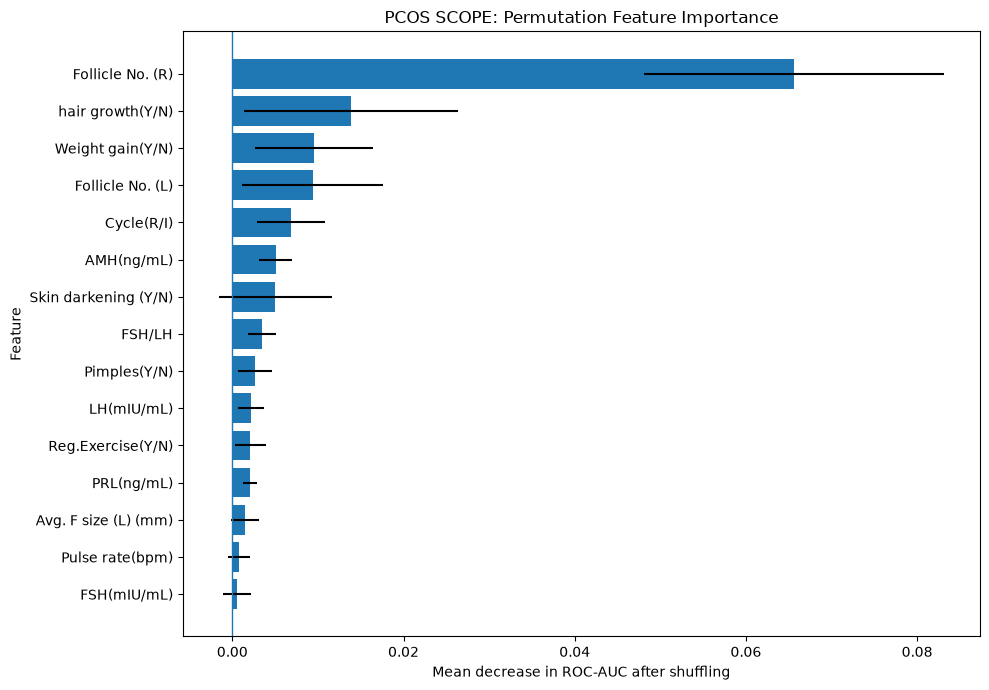

In [45]:

# STEP 25.1: E6 - Explainability using permutation importance

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance

# Use the full-feature Random Forest pipeline trained in E4
# It uses the 40 features from the five main feature groups.

print("Calculating permutation importance...")

importance_result = permutation_importance(
    estimator=full_model,
    X=X_test_full,
    y=y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create a readable feature-importance table
importance_df = pd.DataFrame({
    "Feature": X_test_full.columns,
    "Importance_Mean": importance_result.importances_mean,
    "Importance_Std": importance_result.importances_std
})

# Connect each feature to its planned feature group
feature_to_group = dict(
    zip(
        main_group_plan["Feature"],
        main_group_plan["Feature_Group"]
    )
)

importance_df["Feature_Group"] = (
    importance_df["Feature"].map(feature_to_group)
)

importance_df = importance_df.sort_values(
    "Importance_Mean",
    ascending=False
).reset_index(drop=True)

# Save the complete results
reports_folder = project_folder / "reports"
reports_folder.mkdir(parents=True, exist_ok=True)

importance_path = (
    reports_folder / "permutation_feature_importance.csv"
)

importance_df.to_csv(importance_path, index=False)

print("\nE6 RESULTS: TOP 20 FEATURES")
display(importance_df.head(20).round(4))

print("\nComplete results saved to:")
print(importance_path)

# Plot the 15 highest-ranked features
top_features = (
    importance_df.head(15)
    .sort_values("Importance_Mean", ascending=True)
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance_Mean"],
    xerr=top_features["Importance_Std"]
)

plt.axvline(0, linewidth=1)
plt.xlabel("Mean decrease in ROC-AUC after shuffling")
plt.ylabel("Feature")
plt.title("PCOS SCOPE: Permutation Feature Importance")
plt.tight_layout()
plt.show()


In [47]:

# Update experiment tracker

experiment_plan_path = (
    project_folder / "reports" / "experiment_plan.csv"
)

experiment_plan_df = pd.read_csv(experiment_plan_path)

experiment_plan_df.loc[
    experiment_plan_df["Experiment_ID"] == "E6",
    "Status"
] = "Completed - permutation importance analysis"

experiment_plan_df.to_csv(
    experiment_plan_path,
    index=False
)

display(
    experiment_plan_df[
        ["Experiment_ID", "Experiment_Name", "Status"]
    ]
)

print("E6 status updated.")


,Experiment_ID,Experiment_Name,Status
0,E1,Baseline classification,Planned
1,E2,Individual feature groups,Completed - initial held-out test evaluation
2,E3,Combined feature groups,Completed - initial held-out test evaluation
3,E4,Missing-feature robustness,Completed - random cell-missingness simulation
4,E5,Missing-group robustness,Completed - initial missing-group evaluation
5,E6,Explainability,Completed - permutation importance analysis
6,E7,Explanation stability,Planned
7,E8,BMI handling comparison,Planned


E6 status updated.


Running E7 explanation-stability experiment...
Completed run 1/5
Completed run 2/5
Completed run 3/5
Completed run 4/5
Completed run 5/5

E7 SUMMARY: FEATURE-RANKING STABILITY


,Feature,Mean_Importance,Importance_Across_Run_Std,Mean_Within_Run_Std,Mean_Rank,Rank_Std,Top_10_Count,Feature_Group
0,Follicle No. (R),0.0628,0.0180,0.0167,1.0,0.0000,5,Ovarian measurements
1,hair growth(Y/N),0.0173,0.0045,0.0081,2.4,0.5477,5,Symptoms and lifestyle
2,Skin darkening (Y/N),0.0116,0.0039,0.0068,3.4,0.8944,5,Symptoms and lifestyle
3,Follicle No. (L),0.0122,0.0074,0.0077,4.0,2.0000,5,Ovarian measurements
4,Weight gain(Y/N),0.0064,0.0026,0.0079,5.2,1.3038,5,Symptoms and lifestyle
5,AMH(ng/mL),0.0043,0.0023,0.0039,6.8,1.9235,5,Hormonal and biochemical
6,FSH/LH,0.0040,0.0017,0.0015,7.9,2.5593,4,Hormonal and biochemical
7,LH(mIU/mL),0.0024,0.0009,0.0015,9.1,1.0247,5,Hormonal and biochemical
8,Fast food (Y/N),0.0020,0.0016,0.0027,10.4,2.8810,3,Symptoms and lifestyle
9,Pimples(Y/N),0.0019,0.0015,0.0022,11.8,4.3243,2,Symptoms and lifestyle



Saved run-level results:
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\explanation_stability_runs.csv

Saved summary:
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\explanation_stability_summary.csv


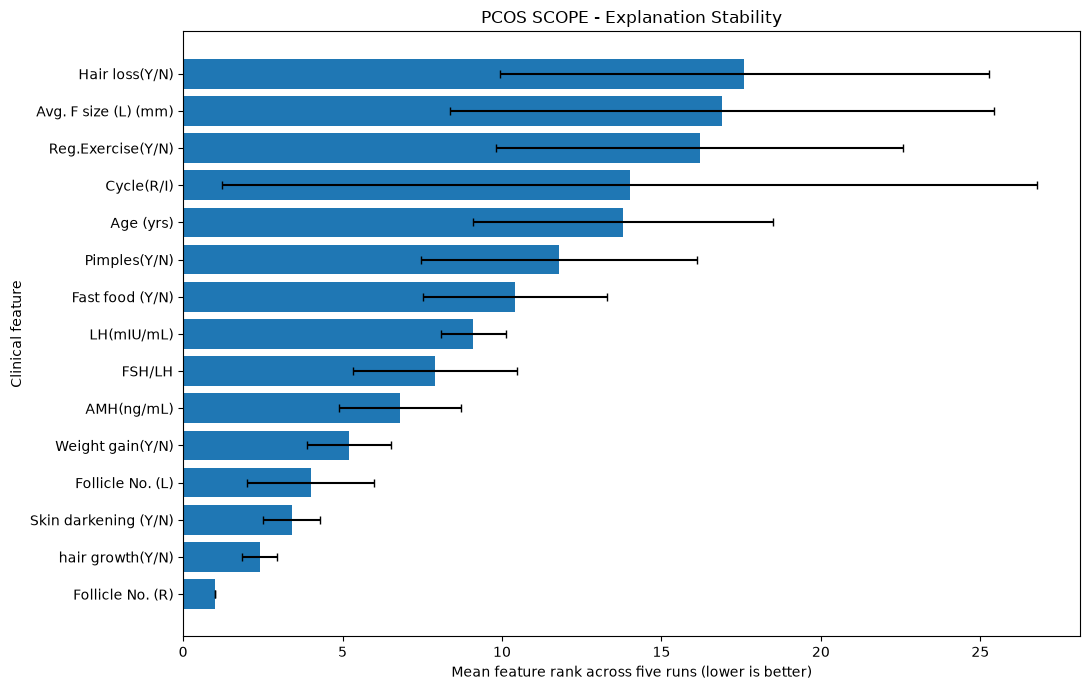


Plot saved to:
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\explanation_stability_plot.png


In [48]:

# STEP 26.2: E7 - Explanation stability across training subsets

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.inspection import permutation_importance

# Use the same 40 main features as E4 and E6
all_features = main_group_plan["Feature"].tolist()

X_train_e7 = X_train[all_features].copy()
X_test_e7 = X_test[all_features].copy()

# Build the categorical/numeric feature lists
categorical_cols = [
    col for col in all_features
    if col in categorical_features
]

numeric_cols = [
    col for col in all_features
    if col in numeric_features
]

# Reuse the full-feature model's preprocessing and classifier setup
# A fresh model is fitted in every run.
base_pipeline = clone(full_model)

# Generate five different stratified subsets from training data only
splitter = StratifiedShuffleSplit(
    n_splits=5,
    test_size=0.20,
    random_state=42
)

stability_runs = []

print("Running E7 explanation-stability experiment...")

for run_number, (subset_indices, _) in enumerate(
    splitter.split(X_train_e7, y_train),
    start=1
):
    X_subset = X_train_e7.iloc[subset_indices]
    y_subset = y_train.iloc[subset_indices]

    # Fit a fresh pipeline on this training subset
    model_run = clone(base_pipeline)
    model_run.fit(X_subset, y_subset)

    # Calculate permutation importance on the same test set
    result = permutation_importance(
        estimator=model_run,
        X=X_test_e7,
        y=y_test,
        scoring="roc_auc",
        n_repeats=5,
        random_state=100 + run_number,
        n_jobs=-1
    )

    run_df = pd.DataFrame({
        "Run": run_number,
        "Feature": X_test_e7.columns,
        "Importance_Mean": result.importances_mean,
        "Importance_Std": result.importances_std
    })

    stability_runs.append(run_df)

    print(f"Completed run {run_number}/5")

# Combine results from all runs
stability_raw_df = pd.concat(
    stability_runs,
    ignore_index=True
)

# Summarise the importance and ranking for each feature
stability_summary_df = (
    stability_raw_df
    .groupby("Feature")
    .agg(
        Mean_Importance=("Importance_Mean", "mean"),
        Importance_Across_Run_Std=("Importance_Mean", "std"),
        Mean_Within_Run_Std=("Importance_Std", "mean")
    )
    .reset_index()
)

# Rank features within each run; rank 1 is most important
stability_raw_df["Rank"] = (
    stability_raw_df
    .groupby("Run")["Importance_Mean"]
    .rank(method="average", ascending=False)
)

rank_summary_df = (
    stability_raw_df
    .groupby("Feature")
    .agg(
        Mean_Rank=("Rank", "mean"),
        Rank_Std=("Rank", "std"),
        Top_10_Count=("Rank", lambda ranks: int((ranks <= 10).sum()))
    )
    .reset_index()
)

stability_summary_df = stability_summary_df.merge(
    rank_summary_df,
    on="Feature",
    how="left"
)

feature_to_group = dict(
    zip(
        main_group_plan["Feature"],
        main_group_plan["Feature_Group"]
    )
)

stability_summary_df["Feature_Group"] = (
    stability_summary_df["Feature"].map(feature_to_group)
)

stability_summary_df = stability_summary_df.sort_values(
    ["Mean_Rank", "Mean_Importance"],
    ascending=[True, False]
).reset_index(drop=True)

# Save raw run-level results and summary
reports_folder = project_folder / "reports"
reports_folder.mkdir(parents=True, exist_ok=True)

raw_path = reports_folder / "explanation_stability_runs.csv"
summary_path = reports_folder / "explanation_stability_summary.csv"

stability_raw_df.to_csv(raw_path, index=False)
stability_summary_df.to_csv(summary_path, index=False)

print("\nE7 SUMMARY: FEATURE-RANKING STABILITY")
display(stability_summary_df.head(20).round(4))

print("\nSaved run-level results:")
print(raw_path)

print("\nSaved summary:")
print(summary_path)

# Plot the top 15 features by mean ranking
plot_data = (
    stability_summary_df
    .head(15)
    .sort_values("Mean_Rank", ascending=True)
)

plt.figure(figsize=(11, 7))

plt.barh(
    plot_data["Feature"],
    plot_data["Mean_Rank"],
    xerr=plot_data["Rank_Std"],
    capsize=3
)

plt.xlabel("Mean feature rank across five runs (lower is better)")
plt.ylabel("Clinical feature")
plt.title("PCOS SCOPE - Explanation Stability")
plt.tight_layout()

plot_path = reports_folder / "explanation_stability_plot.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nPlot saved to:")
print(plot_path)


In [49]:

# STEP 26.3: Update E7 status

experiment_plan_path = (
    project_folder / "reports" / "experiment_plan.csv"
)

experiment_plan_df = pd.read_csv(experiment_plan_path)

experiment_plan_df.loc[
    experiment_plan_df["Experiment_ID"] == "E7",
    "Status"
] = "Completed - five-run explanation stability analysis"

experiment_plan_df.to_csv(
    experiment_plan_path,
    index=False
)

display(
    experiment_plan_df[
        ["Experiment_ID", "Experiment_Name", "Status"]
    ]
)

print("E7 status updated successfully.")


,Experiment_ID,Experiment_Name,Status
0,E1,Baseline classification,Planned
1,E2,Individual feature groups,Completed - initial held-out test evaluation
2,E3,Combined feature groups,Completed - initial held-out test evaluation
3,E4,Missing-feature robustness,Completed - random cell-missingness simulation
4,E5,Missing-group robustness,Completed - initial missing-group evaluation
5,E6,Explainability,Completed - permutation importance analysis
6,E7,Explanation stability,Completed - five-run explanation stability ana...
7,E8,BMI handling comparison,Planned


E7 status updated successfully.


Training: With recorded BMI
Training: Without recorded BMI

E8 RESULTS: BMI HANDLING COMPARISON


,Model,Feature_Count,Accuracy,Sensitivity,Specificity,Precision,F1_Score,ROC_AUC,TN,FP,FN,TP
0,With recorded BMI,40,0.9083,0.8333,0.9452,0.8824,0.8571,0.9425,69,4,6,30
1,Without recorded BMI,39,0.9174,0.8333,0.9589,0.9091,0.8696,0.9433,70,3,6,30



Results saved to:
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\bmi_handling_comparison.csv


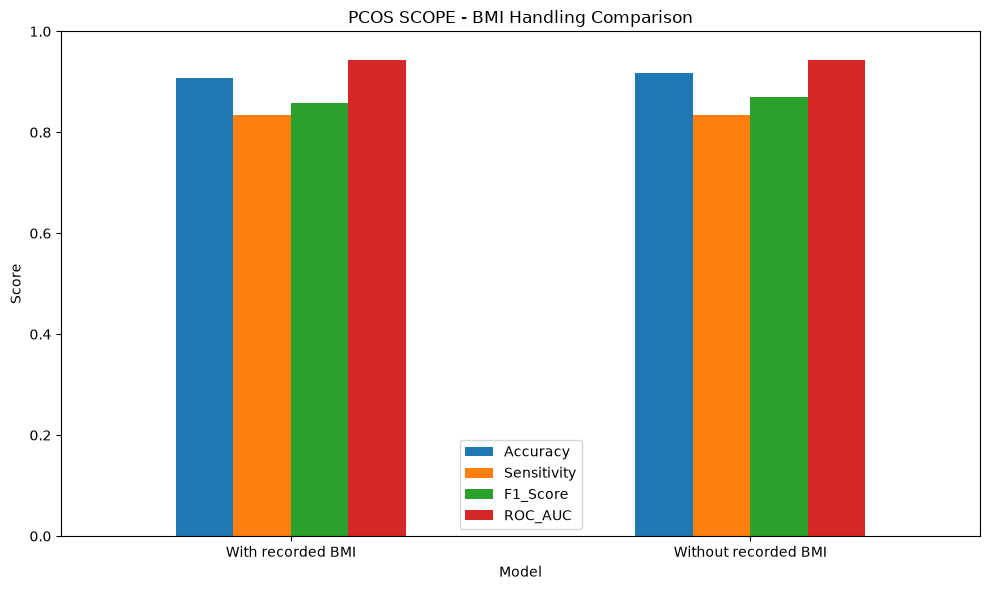


Plot saved to:
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\bmi_handling_comparison.png


In [51]:

# STEP 27.1 FIX: E8 - BMI handling comparison

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Define the two feature configurations
all_features = main_group_plan["Feature"].tolist()

if "BMI" not in all_features:
    raise ValueError(
        "BMI was not found in main_group_plan. "
        "Check the exact feature name before continuing."
    )

feature_configurations = {
    "With recorded BMI": all_features.copy(),
    "Without recorded BMI": [
        feature for feature in all_features
        if feature != "BMI"
    ]
}

bmi_results = []

for model_name, selected_features in feature_configurations.items():

    print(f"Training: {model_name}")

    # Identify feature types for THIS configuration
    selected_numeric = [
        col for col in selected_features
        if col in numeric_features
    ]

    selected_categorical = [
        col for col in selected_features
        if col in categorical_features
    ]

    transformers = []

    if selected_numeric:
        transformers.append((
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            selected_numeric
        ))

    if selected_categorical:
        transformers.append((
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            selected_categorical
        ))

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42
        ))
    ])

    X_train_selected = X_train[selected_features].copy()
    X_test_selected = X_test[selected_features].copy()

    model.fit(X_train_selected, y_train)

    predictions = model.predict(X_test_selected)
    probabilities = model.predict_proba(X_test_selected)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    bmi_results.append({
        "Model": model_name,
        "Feature_Count": len(selected_features),
        "Accuracy": accuracy_score(y_test, predictions),
        "Sensitivity": recall_score(
            y_test, predictions, zero_division=0
        ),
        "Specificity": tn / (tn + fp) if (tn + fp) else 0,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

bmi_results_df = pd.DataFrame(bmi_results)

print("\nE8 RESULTS: BMI HANDLING COMPARISON")
display(bmi_results_df.round(4))

# Save results
reports_folder = project_folder / "reports"
reports_folder.mkdir(parents=True, exist_ok=True)

bmi_results_path = reports_folder / "bmi_handling_comparison.csv"
bmi_results_df.to_csv(bmi_results_path, index=False)

print("\nResults saved to:")
print(bmi_results_path)

# Create and save comparison plot
metrics = ["Accuracy", "Sensitivity", "F1_Score", "ROC_AUC"]

plot_data = bmi_results_df.set_index("Model")[metrics]

ax = plot_data.plot(kind="bar", figsize=(10, 6))

ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_title("PCOS SCOPE - BMI Handling Comparison")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

plt.tight_layout()

bmi_plot_path = reports_folder / "bmi_handling_comparison.png"
plt.savefig(bmi_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nPlot saved to:")
print(bmi_plot_path)



In [52]:

# STEP 27.2: Update E1 and E8 statuses

experiment_plan_path = (
    project_folder / "reports" / "experiment_plan.csv"
)

experiment_plan_df = pd.read_csv(experiment_plan_path)

experiment_plan_df.loc[
    experiment_plan_df["Experiment_ID"] == "E1",
    "Status"
] = "Completed - baseline models and cross-validation"

experiment_plan_df.loc[
    experiment_plan_df["Experiment_ID"] == "E8",
    "Status"
] = "Completed - BMI inclusion versus exclusion"

experiment_plan_df.to_csv(
    experiment_plan_path,
    index=False
)

display(
    experiment_plan_df[
        ["Experiment_ID", "Experiment_Name", "Status"]
    ]
)

print("\nE1 and E8 statuses updated.")


,Experiment_ID,Experiment_Name,Status
0,E1,Baseline classification,Completed - baseline models and cross-validation
1,E2,Individual feature groups,Completed - initial held-out test evaluation
2,E3,Combined feature groups,Completed - initial held-out test evaluation
3,E4,Missing-feature robustness,Completed - random cell-missingness simulation
4,E5,Missing-group robustness,Completed - initial missing-group evaluation
5,E6,Explainability,Completed - permutation importance analysis
6,E7,Explanation stability,Completed - five-run explanation stability ana...
7,E8,BMI handling comparison,Completed - BMI inclusion versus exclusion



E1 and E8 statuses updated.


In [53]:

# STEP 28.1: Compile all PCOS SCOPE experiment results

import pandas as pd
from pathlib import Path

reports_folder = project_folder / "reports"
reports_folder.mkdir(parents=True, exist_ok=True)

# Existing experiment outputs
report_files = {
    "Experiment Tracker": "experiment_plan.csv",
    "Baseline Comparison": "baseline_model_comparison.csv",
    "Cross Validation": "cross_validation_results.csv",
    "Individual Groups": "individual_feature_group_results.csv",
    "Combined Groups": "combined_feature_group_results.csv",
    "Missing Values": "missing_feature_robustness_summary.csv",
    "Missing Groups": "missing_group_robustness_results.csv",
    "Permutation Importance": "permutation_feature_importance.csv",
    "Explanation Stability": "explanation_stability_summary.csv",
    "BMI Comparison": "bmi_handling_comparison.csv"
}

compiled_path = reports_folder / "PCOS_SCOPE_Compiled_Results.xlsx"

loaded_reports = {}
missing_files = []

for sheet_name, filename in report_files.items():
    file_path = reports_folder / filename

    if file_path.exists():
        loaded_reports[sheet_name] = pd.read_csv(file_path)
        print(f"Loaded: {filename}")
    else:
        missing_files.append(filename)
        print(f"Not found: {filename}")

# Write all available reports into separate worksheets
with pd.ExcelWriter(
    compiled_path,
    engine="openpyxl"
) as writer:

    # Overview sheet
    overview = pd.DataFrame({
        "Item": [
            "Project",
            "Purpose",
            "Dataset size",
            "Target",
            "Evaluation note",
            "Missing report files"
        ],
        "Details": [
            "PCOS SCOPE",
            "Explainable group-aware PCOS classification under incomplete clinical data",
            "541 records before train/test split",
            "PCOS (Y/N)",
            "Results are preliminary and based on one dataset and a fixed held-out split unless stated otherwise.",
            ", ".join(missing_files) if missing_files else "None"
        ]
    })

    overview.to_excel(
        writer,
        sheet_name="Project Overview",
        index=False
    )

    for sheet_name, report_df in loaded_reports.items():
        # Excel worksheet names have a 31-character limit
        safe_sheet_name = sheet_name[:31]

        report_df.to_excel(
            writer,
            sheet_name=safe_sheet_name,
            index=False
        )

print("\nConsolidated workbook created:")
print(compiled_path)

print("\nWorksheets included:")
for sheet_name in ["Project Overview", *loaded_reports.keys()]:
    print("-", sheet_name)

if missing_files:
    print("\nPlease check these missing files:")
    for filename in missing_files:
        print("-", filename)


Loaded: experiment_plan.csv
Loaded: baseline_model_comparison.csv
Loaded: cross_validation_results.csv
Loaded: individual_feature_group_results.csv
Loaded: combined_feature_group_results.csv
Loaded: missing_feature_robustness_summary.csv
Loaded: missing_group_robustness_results.csv
Loaded: permutation_feature_importance.csv
Loaded: explanation_stability_summary.csv
Loaded: bmi_handling_comparison.csv

Consolidated workbook created:
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\PCOS_SCOPE_Compiled_Results.xlsx

Worksheets included:
- Project Overview
- Experiment Tracker
- Baseline Comparison
- Cross Validation
- Individual Groups
- Combined Groups
- Missing Values
- Missing Groups
- Permutation Importance
- Explanation Stability
- BMI Comparison


In [54]:

# STEP 29.1: Audit diagnostic-overlap features

import pandas as pd

reports_folder = project_folder / "reports"

feature_plan_path = (
    reports_folder / "provisional_feature_group_plan_v2.csv"
)

feature_plan = pd.read_csv(feature_plan_path)

# Features that deserve closer review because they may overlap
# with the clinical diagnostic process.
review_terms = [
    "follicle",
    "avg. f size",
    "endometrium",
    "amh",
    "lh",
    "fsh",
    "cycle",
    "hair growth",
    "skin darkening",
    "weight gain"
]

feature_plan["Diagnostic_Overlap_Review"] = (
    feature_plan["Feature"].astype(str).str.lower()
    .apply(
        lambda feature: any(
            term in feature for term in review_terms
        )
    )
)

review_table = feature_plan.loc[
    feature_plan["Diagnostic_Overlap_Review"],
    ["Feature_Group", "Feature", "Status"]
].sort_values(["Feature_Group", "Feature"])

print("FEATURES REQUIRING CLINICAL-OVERLAP REVIEW")
display(review_table.reset_index(drop=True))

print("\nNumber of flagged features:", len(review_table))

review_path = reports_folder / "diagnostic_overlap_review.csv"
review_table.to_csv(review_path, index=False)

print("\nAudit list saved to:")
print(review_path)


FEATURES REQUIRING CLINICAL-OVERLAP REVIEW


,Feature_Group,Feature,Status
0,Hormonal and biochemical,AMH(ng/mL),Provisional - review before modelling
1,Hormonal and biochemical,FSH(mIU/mL),Provisional - review before modelling
2,Hormonal and biochemical,FSH/LH,Provisional - review before modelling
3,Hormonal and biochemical,LH(mIU/mL),Provisional - review before modelling
4,Menstrual and reproductive history,Cycle length(days),Provisional - review before modelling
5,Menstrual and reproductive history,Cycle(R/I),Provisional - review before modelling
6,Ovarian measurements,Avg. F size (L) (mm),Provisional - review before modelling
7,Ovarian measurements,Avg. F size (R) (mm),Provisional - review before modelling
8,Ovarian measurements,Endometrium (mm),Provisional - review before modelling
9,Ovarian measurements,Follicle No. (L),Provisional - review before modelling



Number of flagged features: 14

Audit list saved to:
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\diagnostic_overlap_review.csv


In [55]:

# STEP 29.3: Full vs reduced-feature sensitivity analysis

import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Use the existing, verified feature-group plan
plan = feature_group_plan.copy()

all_features = main_group_plan["Feature"].tolist()

# Identify groups by their names in the plan
group_names = plan["Feature_Group"].astype(str).str.lower()

excluded_groups = plan.loc[
    group_names.str.contains("ovarian|hormonal|biochemical"),
    "Feature"
].drop_duplicates().tolist()

# Keep only features included in the current 40-feature model
excluded_features = [
    feature for feature in excluded_groups
    if feature in all_features
]

reduced_features = [
    feature for feature in all_features
    if feature not in excluded_features
]

print("Full model features:", len(all_features))
print("Excluded ovarian/hormonal features:", len(excluded_features))
print("Reduced model features:", len(reduced_features))

print("\nFeatures excluded:")
print(excluded_features)

configurations = {
    "Full clinical model": all_features,
    "Reduced model - no ovarian/hormonal features": reduced_features
}

audit_results = []

for model_name, selected_features in configurations.items():

    print("\nTraining:", model_name)

    numeric_selected = [
        col for col in selected_features
        if col in numeric_features
    ]

    categorical_selected = [
        col for col in selected_features
        if col in categorical_features
    ]

    transformers = []

    if numeric_selected:
        transformers.append((
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            numeric_selected
        ))

    if categorical_selected:
        transformers.append((
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_selected
        ))

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42
        ))
    ])

    X_train_selected = X_train[selected_features].copy()
    X_test_selected = X_test[selected_features].copy()

    model.fit(X_train_selected, y_train)

    predictions = model.predict(X_test_selected)
    probabilities = model.predict_proba(X_test_selected)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    audit_results.append({
        "Model": model_name,
        "Feature_Count": len(selected_features),
        "Accuracy": accuracy_score(y_test, predictions),
        "Sensitivity": recall_score(
            y_test, predictions, zero_division=0
        ),
        "Specificity": tn / (tn + fp) if (tn + fp) else 0,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

audit_results_df = pd.DataFrame(audit_results)

print("\nDIAGNOSTIC-FEATURE SENSITIVITY RESULTS")
display(audit_results_df.round(4))

output_path = (
    project_folder / "reports"
    / "diagnostic_feature_sensitivity_results.csv"
)

audit_results_df.to_csv(output_path, index=False)

print("\nResults saved to:")
print(output_path)


Full model features: 40
Excluded ovarian/hormonal features: 15
Reduced model features: 25

Features excluded:
['I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)', 'FSH(mIU/mL)', 'LH(mIU/mL)', 'FSH/LH', 'TSH (mIU/L)', 'AMH(ng/mL)', 'PRL(ng/mL)', 'Vit D3 (ng/mL)', 'PRG(ng/mL)', 'Follicle No. (L)', 'Follicle No. (R)', 'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)']

Training: Full clinical model

Training: Reduced model - no ovarian/hormonal features

DIAGNOSTIC-FEATURE SENSITIVITY RESULTS


,Model,Feature_Count,Accuracy,Sensitivity,Specificity,Precision,F1_Score,ROC_AUC,TN,FP,FN,TP
0,Full clinical model,40,0.9083,0.8333,0.9452,0.8824,0.8571,0.9425,69,4,6,30
1,Reduced model - no ovarian/hormonal features,25,0.8349,0.7500,0.8767,0.7500,0.7500,0.8946,64,9,9,27



Results saved to:
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\diagnostic_feature_sensitivity_results.csv


In [56]:

# STEP 29.5: Register E9 in the experiment tracker

import pandas as pd

tracker_path = project_folder / "reports" / "experiment_plan.csv"

tracker = pd.read_csv(tracker_path)

# Avoid creating a duplicate if this cell is run again
if "E9" not in tracker["Experiment_ID"].astype(str).values:

    new_experiment = {
        "Experiment_ID": "E9",
        "Experiment_Name": "Diagnostic-feature sensitivity analysis",
        "Status": (
            "Completed - exploratory comparison of full "
            "and reduced feature sets"
        )
    }

    # Preserve any additional columns in the existing tracker
    for column in tracker.columns:
        if column not in new_experiment:
            new_experiment[column] = ""

    tracker = pd.concat(
        [tracker, pd.DataFrame([new_experiment])[tracker.columns]],
        ignore_index=True
    )

else:
    tracker.loc[
        tracker["Experiment_ID"].astype(str) == "E9",
        "Status"
    ] = (
        "Completed - exploratory comparison of full "
        "and reduced feature sets"
    )

tracker.to_csv(tracker_path, index=False)

display(tracker[["Experiment_ID", "Experiment_Name", "Status"]])

print("\nE9 recorded in the experiment tracker.")


,Experiment_ID,Experiment_Name,Status
0,E1,Baseline classification,Completed - baseline models and cross-validation
1,E2,Individual feature groups,Completed - initial held-out test evaluation
2,E3,Combined feature groups,Completed - initial held-out test evaluation
3,E4,Missing-feature robustness,Completed - random cell-missingness simulation
4,E5,Missing-group robustness,Completed - initial missing-group evaluation
5,E6,Explainability,Completed - permutation importance analysis
6,E7,Explanation stability,Completed - five-run explanation stability ana...
7,E8,BMI handling comparison,Completed - BMI inclusion versus exclusion
8,E9,Diagnostic-feature sensitivity analysis,Completed - exploratory comparison of full and...



E9 recorded in the experiment tracker.


In [57]:

# STEP 30: Update the compiled workbook with E9

import pandas as pd

reports_folder = project_folder / "reports"
workbook_path = reports_folder / "PCOS_SCOPE_Compiled_Results.xlsx"

report_files = {
    "Experiment Tracker": "experiment_plan.csv",
    "Baseline Comparison": "baseline_model_comparison.csv",
    "Cross Validation": "cross_validation_results.csv",
    "Individual Groups": "individual_feature_group_results.csv",
    "Combined Groups": "combined_feature_group_results.csv",
    "Missing Values": "missing_feature_robustness_summary.csv",
    "Missing Groups": "missing_group_robustness_results.csv",
    "Permutation Importance": "permutation_feature_importance.csv",
    "Explanation Stability": "explanation_stability_summary.csv",
    "BMI Comparison": "bmi_handling_comparison.csv",
    "E9 Sensitivity": "diagnostic_feature_sensitivity_results.csv"
}

summary_rows = []

for sheet_name, filename in report_files.items():
    path = reports_folder / filename

    if path.exists():
        data = pd.read_csv(path)

        if sheet_name == "Baseline Comparison":
            for _, row in data.iterrows():
                summary_rows.append({
                    "Analysis": "Baseline model",
                    "Configuration": row.get("Model", "See worksheet"),
                    "Accuracy": row.get("Accuracy", None),
                    "Sensitivity": row.get("Sensitivity", None),
                    "F1_Score": row.get("F1_Score", None),
                    "ROC_AUC": row.get("ROC_AUC", None),
                    "Interpretation": "Initial held-out test result"
                })

        elif sheet_name == "E9 Sensitivity":
            for _, row in data.iterrows():
                summary_rows.append({
                    "Analysis": "Diagnostic-feature sensitivity",
                    "Configuration": row.get("Model", "See worksheet"),
                    "Accuracy": row.get("Accuracy", None),
                    "Sensitivity": row.get("Sensitivity", None),
                    "F1_Score": row.get("F1_Score", None),
                    "ROC_AUC": row.get("ROC_AUC", None),
                    "Interpretation": (
                        "Exploratory result; reduced feature set "
                        "excludes hormonal and ovarian groups"
                    )
                })

        print("Included:", filename)
    else:
        print("Missing:", filename)

key_results = pd.DataFrame(summary_rows)

with pd.ExcelWriter(workbook_path, engine="openpyxl") as writer:

    overview = pd.DataFrame({
        "Item": [
            "Project",
            "Research title",
            "Dataset",
            "Number of records",
            "Target",
            "Experiments",
            "Important limitation"
        ],
        "Details": [
            "PCOS SCOPE",
            "An Explainable Group-Aware Machine Learning Framework "
            "for PCOS Classification Under Incomplete Clinical Data",
            "One tabular clinical dataset",
            541,
            "PCOS (Y/N)",
            "E1-E9",
            "Results are exploratory; repeated use of the same "
            "test set limits independent performance claims."
        ]
    })

    overview.to_excel(
        writer, sheet_name="Project Overview", index=False
    )

    key_results.to_excel(
        writer, sheet_name="Key Results Summary", index=False
    )

    for sheet_name, filename in report_files.items():
        path = reports_folder / filename

        if path.exists():
            data = pd.read_csv(path)
            data.to_excel(
                writer,
                sheet_name=sheet_name[:31],
                index=False
            )

print("\nUpdated workbook saved to:")
print(workbook_path)

print("\nKey Results Summary:")
display(key_results.round(4))


Included: experiment_plan.csv
Included: baseline_model_comparison.csv
Included: cross_validation_results.csv
Included: individual_feature_group_results.csv
Included: combined_feature_group_results.csv
Included: missing_feature_robustness_summary.csv
Included: missing_group_robustness_results.csv
Included: permutation_feature_importance.csv
Included: explanation_stability_summary.csv
Included: bmi_handling_comparison.csv
Included: diagnostic_feature_sensitivity_results.csv

Updated workbook saved to:
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\PCOS_SCOPE_Compiled_Results.xlsx

Key Results Summary:


,Analysis,Configuration,Accuracy,Sensitivity,F1_Score,ROC_AUC,Interpretation
0,Baseline model,Logistic Regression (balanced),0.8716,0.8889,0.8205,0.9505,Initial held-out test result
1,Baseline model,Random Forest (balanced),0.9083,0.8333,0.8571,0.9467,Initial held-out test result
2,Diagnostic-feature sensitivity,Full clinical model,0.9083,0.8333,0.8571,0.9425,Exploratory result; reduced feature set exclud...
3,Diagnostic-feature sensitivity,Reduced model - no ovarian/hormonal features,0.8349,0.7500,0.7500,0.8946,Exploratory result; reduced feature set exclud...


In [58]:

# STEP 32.1: Inspect existing validation reports

import pandas as pd

reports_folder = project_folder / "reports"

files_to_check = [
    "cross_validation_results.csv",
    "baseline_model_comparison.csv"
]

for filename in files_to_check:

    file_path = reports_folder / filename

    print("\n" + "=" * 60)
    print("FILE:", filename)
    print("=" * 60)

    if file_path.exists():
        report = pd.read_csv(file_path)

        print("Rows:", report.shape[0])
        print("Columns:", report.columns.tolist())

        display(report)

        if "cross_validation" in filename:
            print(
                "\nCheck: These results should be based on "
                "training-set folds, not the held-out test set."
            )
    else:
        print("FILE NOT FOUND:", file_path)

print("\nValidation report inspection completed.")



FILE: cross_validation_results.csv
Rows: 8
Columns: ['Model', 'Metric', 'Mean_CV_Score', 'Std_CV_Score']


,Model,Metric,Mean_CV_Score,Std_CV_Score
0,Logistic Regression (balanced),ROC_AUC,0.928008,0.015689
1,Logistic Regression (balanced),F1_Score,0.814964,0.040450
2,Logistic Regression (balanced),Sensitivity,0.865517,0.024795
3,Logistic Regression (balanced),Accuracy,0.870543,0.033106
4,Random Forest (balanced),ROC_AUC,0.953692,0.016830
5,Random Forest (balanced),F1_Score,0.853671,0.050565
6,Random Forest (balanced),Sensitivity,0.851232,0.025495
7,Random Forest (balanced),Accuracy,0.902967,0.038584



Check: These results should be based on training-set folds, not the held-out test set.

FILE: baseline_model_comparison.csv
Rows: 2
Columns: ['Model', 'Accuracy', 'Sensitivity', 'Specificity', 'F1_Score', 'ROC_AUC']


,Model,Accuracy,Sensitivity,Specificity,F1_Score,ROC_AUC
0,Logistic Regression (balanced),0.871560,0.888889,0.863014,0.820513,0.950533
1,Random Forest (balanced),0.908257,0.833333,0.945205,0.857143,0.946728



Validation report inspection completed.


In [59]:

# STEP 32.3: Repeated cross-validation for feature settings

import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

# Full and reduced feature sets from the previous experiment
all_features = main_group_plan["Feature"].tolist()

plan = feature_group_plan.copy()
group_names = plan["Feature_Group"].astype(str).str.lower()

excluded_features = plan.loc[
    group_names.str.contains("ovarian|hormonal|biochemical"),
    "Feature"
].drop_duplicates().tolist()

excluded_features = [
    col for col in excluded_features if col in all_features
]

reduced_features = [
    col for col in all_features if col not in excluded_features
]

configurations = {
    "Full clinical model": all_features,
    "Reduced model": reduced_features
}

# Repeated, stratified 5-fold cross-validation
cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "sensitivity": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = []

for model_name, selected_features in configurations.items():

    print("Evaluating:", model_name)

    selected_numeric = [
        col for col in selected_features
        if col in numeric_features
    ]

    selected_categorical = [
        col for col in selected_features
        if col in categorical_features
    ]

    transformers = []

    if selected_numeric:
        transformers.append((
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            selected_numeric
        ))

    if selected_categorical:
        transformers.append((
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            selected_categorical
        ))

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42
        ))
    ])

    X_selected = X[selected_features].copy()

    scores = cross_validate(
        model,
        X_selected,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    for metric in scoring:
        values = scores[f"test_{metric}"]

        cv_results.append({
            "Model": model_name,
            "Feature_Count": len(selected_features),
            "Metric": metric,
            "Mean_CV_Score": values.mean(),
            "Std_CV_Score": values.std()
        })

cv_results_df = pd.DataFrame(cv_results)

print("\nREPEATED CROSS-VALIDATION RESULTS")
display(cv_results_df.round(4))

output_path = (
    project_folder / "reports"
    / "repeated_cv_full_vs_reduced.csv"
)

cv_results_df.to_csv(output_path, index=False)

print("\nResults saved to:")
print(output_path)


Evaluating: Full clinical model
Evaluating: Reduced model

REPEATED CROSS-VALIDATION RESULTS


,Model,Feature_Count,Metric,Mean_CV_Score,Std_CV_Score
0,Full clinical model,40,accuracy,0.9002,0.0186
1,Full clinical model,40,sensitivity,0.8437,0.0728
2,Full clinical model,40,f1,0.8457,0.0333
3,Full clinical model,40,roc_auc,0.9590,0.0158
4,Reduced model,25,accuracy,0.8300,0.0447
5,Reduced model,25,sensitivity,0.7553,0.0804
6,Reduced model,25,f1,0.7437,0.0681
7,Reduced model,25,roc_auc,0.8895,0.0234



Results saved to:
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\repeated_cv_full_vs_reduced.csv


In [60]:

# STEP 32.5: Add repeated cross-validation to compiled workbook

import pandas as pd

reports_folder = project_folder / "reports"

workbook_path = (
    reports_folder / "PCOS_SCOPE_Compiled_Results.xlsx"
)

cv_path = reports_folder / "repeated_cv_full_vs_reduced.csv"

if not cv_path.exists():
    raise FileNotFoundError(
        "Run Step 32.3 first. Repeated CV results were not found."
    )

cv_results_df = pd.read_csv(cv_path)

# Replace this worksheet if it already exists
with pd.ExcelWriter(
    workbook_path,
    engine="openpyxl",
    mode="a",
    if_sheet_exists="replace"
) as writer:

    cv_results_df.to_excel(
        writer,
        sheet_name="Repeated CV",
        index=False
    )

print("Repeated CV worksheet added successfully.")
print("Workbook:", workbook_path)

display(cv_results_df.round(4))


Repeated CV worksheet added successfully.
Workbook: C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\PCOS_SCOPE_Compiled_Results.xlsx


,Model,Feature_Count,Metric,Mean_CV_Score,Std_CV_Score
0,Full clinical model,40,accuracy,0.9002,0.0186
1,Full clinical model,40,sensitivity,0.8437,0.0728
2,Full clinical model,40,f1,0.8457,0.0333
3,Full clinical model,40,roc_auc,0.9590,0.0158
4,Reduced model,25,accuracy,0.8300,0.0447
5,Reduced model,25,sensitivity,0.7553,0.0804
6,Reduced model,25,f1,0.7437,0.0681
7,Reduced model,25,roc_auc,0.8895,0.0234


In [61]:

# STEP 33.1: Document the provisional model-selection decision

research_folder = project_folder / "research"
research_folder.mkdir(parents=True, exist_ok=True)

decision_text = """
PCOS SCOPE - PROVISIONAL MODEL SELECTION
========================================

Selected candidate:
Random Forest with class_weight='balanced'

Input configuration:
Full clinical model using 40 features.

Repeated cross-validation (5 folds x 3 repeats):
Mean accuracy:    0.9002
Mean sensitivity: 0.8437
Mean F1-score:    0.8457
Mean ROC-AUC:     0.9590

Comparison:
The reduced 25-feature model had lower mean scores on all
four metrics in the exploratory repeated-CV evaluation.

Important limitations:
1. The dataset contains 541 records from one dataset.
2. Earlier feature comparisons reused the same held-out test set.
3. Repeated cross-validation is exploratory, not independent
   external validation.
4. Clinical overlap between input features and PCOS labels
   requires careful interpretation.
5. This model is a research prototype, not a diagnostic tool.

Next steps:
- Finalise the methodology and limitations.
- Save and test the preprocessing-plus-model pipeline.
- Build an application that validates inputs and communicates
  limitations clearly.
- Avoid claims of clinical readiness without independent validation.
"""

decision_path = research_folder / "model_selection_decision.txt"
decision_path.write_text(decision_text.strip(), encoding="utf-8")

print("Model-selection record saved to:")
print(decision_path)


Model-selection record saved to:
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\research\model_selection_decision.txt


In [62]:

# STEP 34.1: Train and save the complete Random Forest pipeline

import joblib
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

# Use the 40 features in our approved feature-group plan
selected_features = main_group_plan["Feature"].tolist()

selected_numeric = [
    col for col in selected_features
    if col in numeric_features
]

selected_categorical = [
    col for col in selected_features
    if col in categorical_features
]

transformers = []

if selected_numeric:
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    transformers.append((
        "numeric",
        numeric_pipeline,
        selected_numeric
    ))

if selected_categorical:
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    transformers.append((
        "categorical",
        categorical_pipeline,
        selected_categorical
    ))

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42
    ))
])

# Train only on the training split
X_train_selected = X_train[selected_features].copy()

final_model.fit(X_train_selected, y_train)

# Save the complete pipeline
models_folder = project_folder / "models"
models_folder.mkdir(parents=True, exist_ok=True)

model_path = models_folder / "pcos_scope_random_forest_pipeline.joblib"

joblib.dump(final_model, model_path)

# Save feature metadata for reproducibility
metadata = {
    "model_name": "Random Forest",
    "feature_count": len(selected_features),
    "numeric_features": selected_numeric,
    "categorical_features": selected_categorical,
    "target_column": "PCOS (Y/N)",
    "random_state": 42,
    "n_estimators": 300,
    "class_weight": "balanced"
}

metadata_path = models_folder / "pcos_scope_model_metadata.json"

import json
with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4)

print("Pipeline trained and saved.")
print("Model:", model_path)
print("Metadata:", metadata_path)
print("Features:", len(selected_features))
print("Training records:", len(X_train_selected))


Pipeline trained and saved.
Model: C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\models\pcos_scope_random_forest_pipeline.joblib
Metadata: C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\models\pcos_scope_model_metadata.json
Features: 40
Training records: 432


In [63]:

# STEP 34.2: Reload and verify the saved pipeline

import joblib
import numpy as np

# Load the saved pipeline
loaded_model = joblib.load(model_path)

# Prepare the held-out test data in the correct column order
X_test_selected = X_test[selected_features].copy()

# Compare predictions from both versions
original_predictions = final_model.predict(X_test_selected)
loaded_predictions = loaded_model.predict(X_test_selected)

same_predictions = np.array_equal(
    original_predictions,
    loaded_predictions
)

print("Saved model loaded successfully.")
print("Predictions match:", same_predictions)
print("Test records checked:", len(X_test_selected))
print("Predictions generated:", len(loaded_predictions))

if not same_predictions:
    print("WARNING: Predictions do not match. Investigate before proceeding.")
else:
    print("Verification passed.")


Saved model loaded successfully.
Predictions match: True
Test records checked: 109
Predictions generated: 109
Verification passed.


In [64]:

# STEP 35.1: Inspect prediction probabilities

import pandas as pd
import numpy as np

# Generate predictions and probabilities from the saved model
test_predictions = loaded_model.predict(X_test_selected)
test_probabilities = loaded_model.predict_proba(X_test_selected)

# Identify which probability column corresponds to PCOS = 1
class_labels = loaded_model.named_steps["classifier"].classes_
positive_class_index = list(class_labels).index(1)

pcos_scores = test_probabilities[:, positive_class_index]

probability_results = pd.DataFrame({
    "Actual_PCOS": np.asarray(y_test),
    "Predicted_PCOS": test_predictions,
    "Model_Score": pcos_scores
})

print("Model classes:", class_labels)
print("\nFirst 10 test predictions:")
display(probability_results.head(10).round(4))

print("\nProbability score summary:")
display(probability_results["Model_Score"].describe().round(4))

print(
    "\nAll scores between 0 and 1:",
    bool(
        (probability_results["Model_Score"].between(0, 1)).all()
    )
)


Model classes: [0 1]

First 10 test predictions:


,Actual_PCOS,Predicted_PCOS,Model_Score
0,1,0,0.0700
1,0,0,0.3900
2,0,0,0.2633
3,1,1,0.8467
4,0,0,0.1167
5,1,1,0.8800
6,1,0,0.2867
7,0,0,0.1800
8,1,1,0.6467
9,0,0,0.1000



Probability score summary:


count    109.0000
mean       0.3776
std        0.2973
min        0.0067
25%        0.1067
50%        0.2867
75%        0.6467
max        0.9733
Name: Model_Score, dtype: float64


All scores between 0 and 1: True


In [65]:

# STEP 35.2: Explore classification thresholds

from sklearn.metrics import confusion_matrix

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

actual = np.asarray(y_test)

for threshold in thresholds:
    predictions_at_threshold = (
        pcos_scores >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        actual,
        predictions_at_threshold,
        labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn) if (tp + fn) else 0
    specificity = tn / (tn + fp) if (tn + fp) else 0
    accuracy = (tp + tn) / (tp + tn + fp + fn)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "False_Negatives": fn,
        "False_Positives": fp
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Threshold,Accuracy,Sensitivity,Specificity,False_Negatives,False_Positives
0,0.3,0.7982,0.9167,0.7397,3,19
1,0.4,0.8807,0.9167,0.8630,3,10
2,0.5,0.9083,0.8333,0.9452,6,4
3,0.6,0.9358,0.8333,0.9863,6,1
4,0.7,0.8807,0.6667,0.9863,12,1


In [66]:

# STEP 35.3: Recalculate and verify threshold metrics

from sklearn.metrics import confusion_matrix
import pandas as pd
import numpy as np

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]
actual = np.asarray(y_test).astype(int)

verified_results = []

for threshold in thresholds:
    predicted = (pcos_scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        actual, predicted, labels=[0, 1]
    ).ravel()

    verified_results.append({
        "Threshold": threshold,
        "Accuracy": (tp + tn) / (tp + tn + fp + fn),
        "Sensitivity": tp / (tp + fn) if tp + fn else 0,
        "Specificity": tn / (tn + fp) if tn + fp else 0,
        "False_Negatives": fn,
        "False_Positives": fp,
        "TN": tn,
        "TP": tp
    })

verified_threshold_df = pd.DataFrame(verified_results)

display(verified_threshold_df.round(4))

threshold_path = (
    project_folder / "reports" / "threshold_comparison_verified.csv"
)
verified_threshold_df.to_csv(threshold_path, index=False)

print("\nVerified results saved to:")
print(threshold_path)


,Threshold,Accuracy,Sensitivity,Specificity,False_Negatives,False_Positives,TN,TP
0,0.3,0.7982,0.9167,0.7397,3,19,54,33
1,0.4,0.8807,0.9167,0.8630,3,10,63,33
2,0.5,0.9083,0.8333,0.9452,6,4,69,30
3,0.6,0.9358,0.8333,0.9863,6,1,72,30
4,0.7,0.8807,0.6667,0.9863,12,1,72,24



Verified results saved to:
C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports\threshold_comparison_verified.csv


In [67]:

# STEP 36.1: Verify PCOS SCOPE app prerequisites

from pathlib import Path
import json
import joblib

required_paths = {
    "Saved model": project_folder / "models" / "pcos_scope_random_forest_pipeline.joblib",
    "Model metadata": project_folder / "models" / "pcos_scope_model_metadata.json",
    "Cleaned dataset": project_folder / "data" / "processed" / "pcos_cleaned.csv",
    "Reports folder": project_folder / "reports",
    "App folder": project_folder / "app",
    "Source folder": project_folder / "src"
}

print("PCOS SCOPE — Setup Verification\n")

for name, path in required_paths.items():
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")
    print(f"  {path}")

# Read metadata and verify feature count
metadata_path = required_paths["Model metadata"]

if metadata_path.exists():
    with open(metadata_path, "r", encoding="utf-8") as file:
        metadata = json.load(file)

    print("\nModel metadata:")
    print("Model:", metadata["model_name"])
    print("Feature count:", metadata["feature_count"])

# Ensure the saved pipeline can load
model_path = required_paths["Saved model"]

if model_path.exists():
    app_model = joblib.load(model_path)
    print("\nSaved pipeline loaded successfully.")


PCOS SCOPE — Setup Verification

Saved model: FOUND
  C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\models\pcos_scope_random_forest_pipeline.joblib
Model metadata: FOUND
  C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\models\pcos_scope_model_metadata.json
Cleaned dataset: FOUND
  C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\data\processed\pcos_cleaned.csv
Reports folder: FOUND
  C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\reports
App folder: FOUND
  C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\app
Source folder: FOUND
  C:\Users\deel\OneDrive\Desktop\VIT SEM-5\MACHINE LEARNING\FINAL PROJECT\PCOS_SCOPE\src

Model metadata:
Model: Random Forest
Feature count: 40

Saved pipeline loaded successfully.


In [68]:

# STEP 37.1: Inspect the exact features required by the app

import json
import pandas as pd

metadata_path = (
    project_folder / "models" / "pcos_scope_model_metadata.json"
)

with open(metadata_path, "r", encoding="utf-8") as file:
    metadata = json.load(file)

app_features = (
    metadata["numeric_features"]
    + metadata["categorical_features"]
)

print("Total input features:", len(app_features))
print("\nNumeric features:", len(metadata["numeric_features"]))
print("Categorical features:", len(metadata["categorical_features"]))

feature_reference = pd.DataFrame({
    "Feature": app_features,
    "Type": [
        "Numeric" if col in metadata["numeric_features"]
        else "Categorical"
        for col in app_features
    ]
})

display(feature_reference)


Total input features: 40

Numeric features: 31
Categorical features: 9


,Feature,Type
0,Age (yrs),Numeric
1,Weight (Kg),Numeric
2,Height(Cm),Numeric
3,BMI,Numeric
4,Pulse rate(bpm),Numeric
5,RR (breaths/min),Numeric
6,Hb(g/dl),Numeric
7,Hip(inch),Numeric
8,Waist(inch),Numeric
9,Waist:Hip Ratio,Numeric


In [69]:

# PCOS SCOPE: Diagnose the feature-name mismatch

import json
import pandas as pd

metadata_path = project_folder / "models" / "pcos_scope_model_metadata.json"
data_path = project_folder / "data" / "processed" / "pcos_cleaned.csv"

with open(metadata_path, "r", encoding="utf-8") as file:
    metadata = json.load(file)

df = pd.read_csv(data_path)

expected_features = (
    metadata["numeric_features"]
    + metadata["categorical_features"]
)

print("Expected features:", len(expected_features))
print("Dataset columns:", len(df.columns))

missing_columns = [
    col for col in expected_features
    if col not in df.columns
]

print("\nFEATURES NOT MATCHING THE CSV:")
for col in missing_columns:
    print(repr(col))

print("\nPOSSIBLE MATCHES:")
for missing in missing_columns:
    print(f"\nExpected: {repr(missing)}")
    for actual in df.columns:
        if missing.strip().lower() == actual.strip().lower():
            print(f"  Candidate: {repr(actual)}")


Expected features: 40
Dataset columns: 44

FEATURES NOT MATCHING THE CSV:
'Age (yrs)'
'Height(Cm)'
'Pulse rate(bpm)'
'I   beta-HCG(mIU/mL)'

POSSIBLE MATCHES:

Expected: 'Age (yrs)'
  Candidate: ' Age (yrs)'

Expected: 'Height(Cm)'
  Candidate: 'Height(Cm) '

Expected: 'Pulse rate(bpm)'
  Candidate: 'Pulse rate(bpm) '

Expected: 'I   beta-HCG(mIU/mL)'
  Candidate: '  I   beta-HCG(mIU/mL)'


In [70]:
import json
from pathlib import Path

path = Path("models/pcos_scope_model_metadata.json")

with open(path, "r", encoding="utf-8") as f:
    metadata = json.load(f)

print(json.dumps(metadata, indent=2))

{
  "model_name": "Random Forest",
  "feature_count": 40,
  "numeric_features": [
    "Age (yrs)",
    "Weight (Kg)",
    "Height(Cm)",
    "BMI",
    "Pulse rate(bpm)",
    "RR (breaths/min)",
    "Hb(g/dl)",
    "Hip(inch)",
    "Waist(inch)",
    "Waist:Hip Ratio",
    "RBS(mg/dl)",
    "BP _Systolic (mmHg)",
    "BP _Diastolic (mmHg)",
    "I   beta-HCG(mIU/mL)",
    "II    beta-HCG(mIU/mL)",
    "FSH(mIU/mL)",
    "LH(mIU/mL)",
    "FSH/LH",
    "TSH (mIU/L)",
    "AMH(ng/mL)",
    "PRL(ng/mL)",
    "Vit D3 (ng/mL)",
    "PRG(ng/mL)",
    "Cycle length(days)",
    "Marraige Status (Yrs)",
    "No. of aborptions",
    "Follicle No. (L)",
    "Follicle No. (R)",
    "Avg. F size (L) (mm)",
    "Avg. F size (R) (mm)",
    "Endometrium (mm)"
  ],
  "categorical_features": [
    "Cycle(R/I)",
    "Pregnant(Y/N)",
    "Weight gain(Y/N)",
    "hair growth(Y/N)",
    "Skin darkening (Y/N)",
    "Hair loss(Y/N)",
    "Pimples(Y/N)",
    "Fast food (Y/N)",
    "Reg.Exercise(Y/N)"
  ],
  "ta